# Clustering dei giocatori FC25

## Individuazione di profili tattici con PCA e K-Means

L'analisi considera i giocatori di movimento con `OVR >= 75`. I gruppi vengono costruiti usando le statistiche tecniche dettagliate, mentre le sei statistiche principali (`PAC`, `SHO`, `PAS`, `DRI`, `DEF`, `PHY`) vengono utilizzate soltanto per interpretare i risultati.

La procedura segue questi passaggi:

1. selezione e standardizzazione delle caratteristiche tecniche;
2. riduzione dimensionale conservando almeno l'80% della varianza;
3. confronto fra diversi numeri di cluster;
4. interpretazione dei gruppi attraverso ruoli e statistiche medie.

In [1]:
from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Evita un controllo dei core fisici non consentito in alcuni ambienti Windows.
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams.update({
    'figure.figsize': (14, 7),
    'figure.dpi': 110,
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'legend.frameon': False,
})

DATA_PATH = Path('../data/puliti/movimento_puliti.csv')
FIG_DIR = Path('figure_clustering')
FIG_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
SOGLIA_OVR = 75

# Il reset dell'indice mantiene allineati giocatori, coordinate PCA e cluster.
df_top = (
    df.loc[df['OVR'] >= SOGLIA_OVR]
      .copy()
      .reset_index(drop=True)
)

print(f'Giocatori di movimento totali: {len(df):,}')
print(f'Giocatori con OVR >= {SOGLIA_OVR}: {len(df_top):,}')

Giocatori di movimento totali: 15,738
Giocatori con OVR >= 75: 2,086


## 1. Scelta delle caratteristiche

Il modello usa 29 statistiche tecniche dettagliate. Sono escluse:

- `OVR`, già utilizzato per selezionare il campione;
- età, piede debole, mosse abilità, posizioni alternative e playstyle;
- le statistiche aggregate `PAC`, `SHO`, `PAS`, `DRI`, `DEF`, `PHY`.

Le statistiche aggregate derivano da quelle dettagliate: inserirle entrambe darebbe più peso agli stessi aspetti del giocatore. La PCA gestisce poi le correlazioni residue fra le 29 caratteristiche selezionate.

In [2]:
technical_features = [
    'Acceleration', 'Sprint Speed',
    'Positioning', 'Finishing', 'Shot Power', 'Long Shots', 'Volleys', 'Penalties',
    'Vision', 'Crossing', 'Free Kick Accuracy', 'Short Passing', 'Long Passing', 'Curve',
    'Dribbling', 'Agility', 'Balance', 'Reactions', 'Ball Control', 'Composure',
    'Interceptions', 'Heading Accuracy', 'Def Awareness', 'Standing Tackle', 'Sliding Tackle',
    'Jumping', 'Stamina', 'Strength', 'Aggression',
]

missing_columns = [column for column in technical_features if column not in df_top.columns]
if missing_columns:
    raise ValueError(f'Colonne mancanti: {missing_columns}')

X = df_top[technical_features].copy()
print(f'Feature utilizzate: {X.shape[1]}')
print(f'Valori mancanti: {int(X.isna().sum().sum())}')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Feature utilizzate: 29
Valori mancanti: 0


## 2. Numero di componenti principali

La PCA viene inizialmente calcolata conservando tutte le componenti. Il numero impiegato nel clustering è il minimo necessario per spiegare almeno l'80% della varianza.

Componenti necessarie per almeno l'80%: 6
Varianza complessivamente spiegata: 81.32%


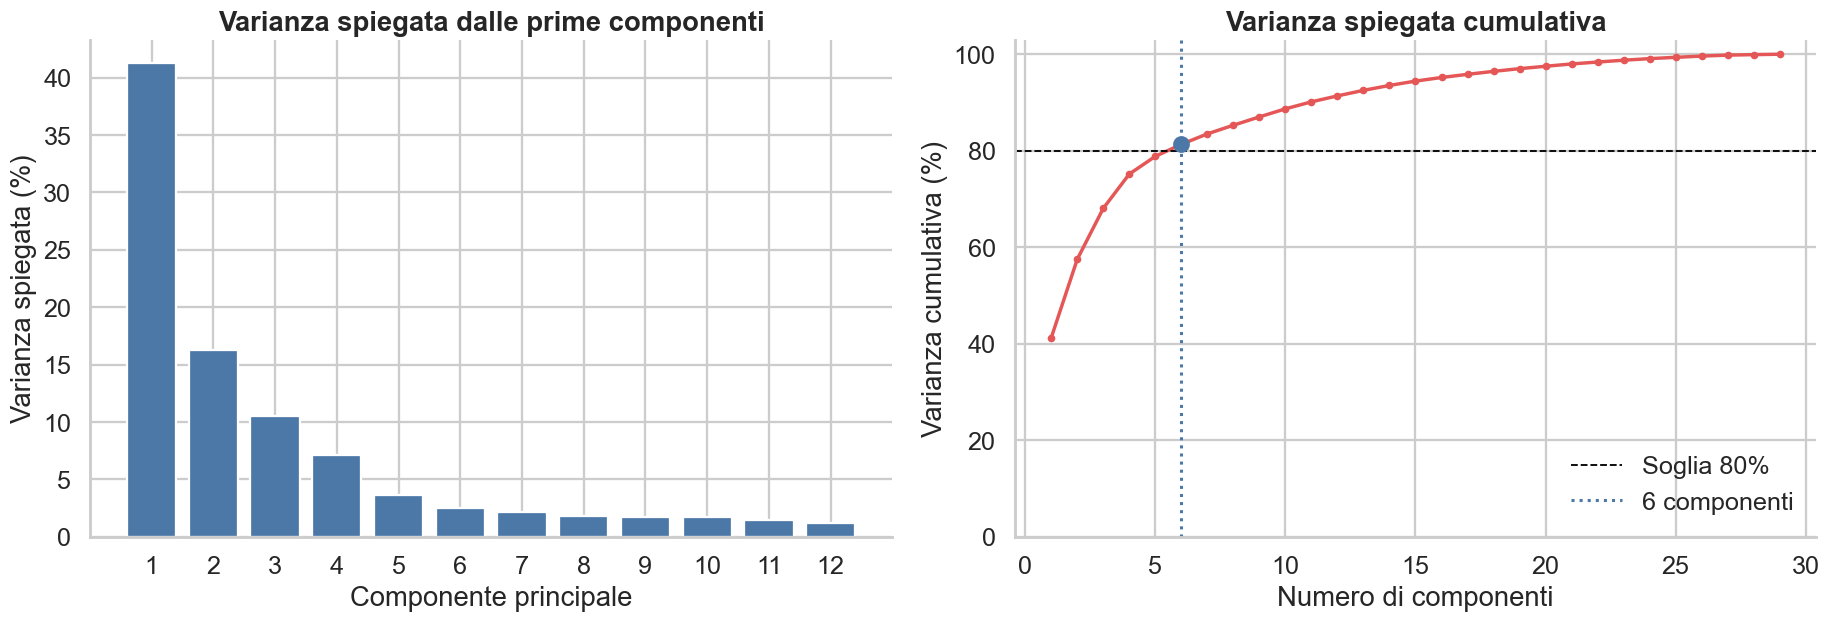

In [3]:
pca_full = PCA().fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
N_COMPONENTS = int(np.argmax(cumulative >= 0.80) + 1)

print(f"Componenti necessarie per almeno l'80%: {N_COMPONENTS}")
print(f'Varianza complessivamente spiegata: {cumulative[N_COMPONENTS - 1] * 100:.2f}%')

component_numbers = np.arange(1, len(explained) + 1)
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

axes[0].bar(component_numbers[:12], explained[:12] * 100, color='#4c78a8')
axes[0].set_title('Varianza spiegata dalle prime componenti')
axes[0].set_xlabel('Componente principale')
axes[0].set_ylabel('Varianza spiegata (%)')
axes[0].set_xticks(component_numbers[:12])

axes[1].plot(component_numbers, cumulative * 100, marker='o', markersize=4, color='#e45756')
axes[1].axhline(80, color='black', linestyle='--', linewidth=1.2, label='Soglia 80%')
axes[1].axvline(N_COMPONENTS, color='#4c78a8', linestyle=':', linewidth=2,
                label=f'{N_COMPONENTS} componenti')
axes[1].scatter([N_COMPONENTS], [cumulative[N_COMPONENTS - 1] * 100],
                color='#4c78a8', s=90, zorder=5)
axes[1].set_title('Varianza spiegata cumulativa')
axes[1].set_xlabel('Numero di componenti')
axes[1].set_ylabel('Varianza cumulativa (%)')
axes[1].set_ylim(0, 103)
axes[1].legend()

fig.tight_layout()
fig.savefig(FIG_DIR / '01_varianza_pca.png', dpi=300, bbox_inches='tight')
plt.show()

pca = PCA(n_components=N_COMPONENTS)
X_pca = pca.fit_transform(X_scaled)

pca_columns = [f'PC{i}' for i in range(1, N_COMPONENTS + 1)]
pca_df = pd.DataFrame(X_pca, columns=pca_columns, index=df_top.index)
loadings = pd.DataFrame(pca.components_.T, index=technical_features, columns=pca_columns)

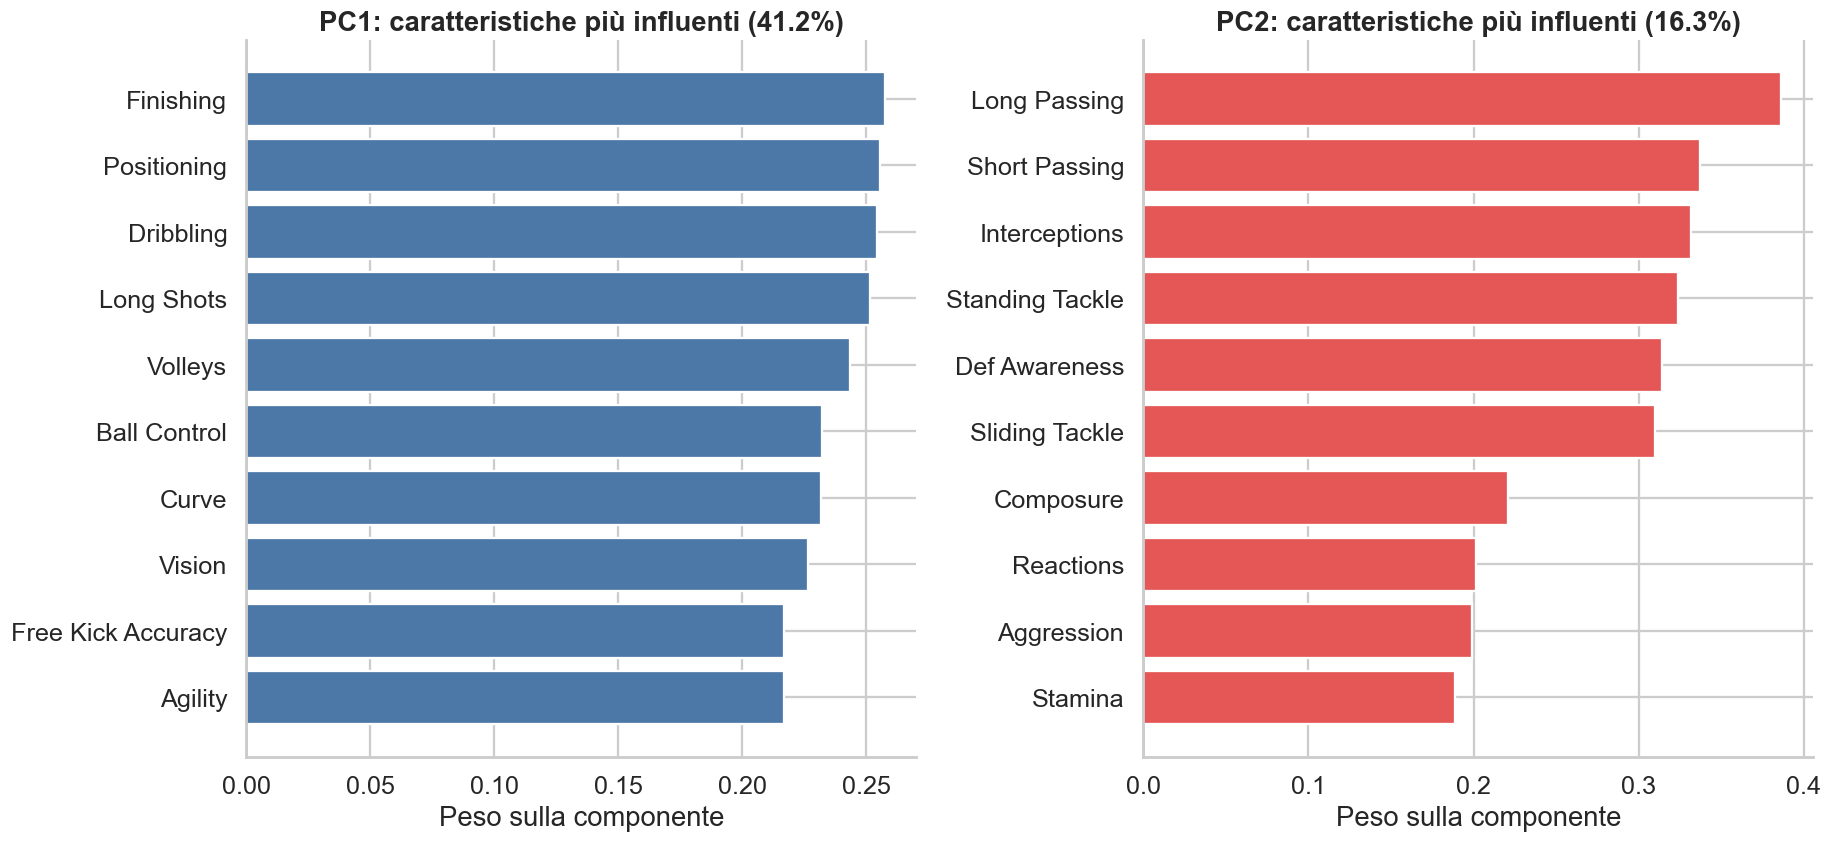


PC1 — caratteristiche con maggiore peso assoluto:


,PC1
Finishing,0.257
Positioning,0.255
Dribbling,0.254
Long Shots,0.252
Volleys,0.243
Ball Control,0.232
Curve,0.232
Vision,0.226



PC2 — caratteristiche con maggiore peso assoluto:


,PC2
Long Passing,0.386
Short Passing,0.337
Interceptions,0.332
Standing Tackle,0.324
Def Awareness,0.314
Sliding Tackle,0.310
Composure,0.221
Reactions,0.202


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8))

for ax, component, color in zip(axes, ['PC1', 'PC2'], ['#4c78a8', '#e45756']):
    values = loadings[component]
    selected = values.loc[values.abs().sort_values().tail(10).index].sort_values()
    bar_colors = [color if value >= 0 else '#9e9e9e' for value in selected]
    ax.barh(selected.index, selected.values, color=bar_colors)
    ax.axvline(0, color='black', linewidth=0.8)
    variance = pca.explained_variance_ratio_[int(component[-1]) - 1] * 100
    ax.set_title(f'{component}: caratteristiche più influenti ({variance:.1f}%)')
    ax.set_xlabel('Peso sulla componente')

fig.tight_layout()
fig.savefig(FIG_DIR / '02_pesi_componenti.png', dpi=300, bbox_inches='tight')
plt.show()

for component in ['PC1', 'PC2']:
    print(f'\n{component} — caratteristiche con maggiore peso assoluto:')
    display(
        loadings[[component]]
        .assign(Peso_assoluto=loadings[component].abs())
        .sort_values('Peso_assoluto', ascending=False)
        .head(8)
        .drop(columns='Peso_assoluto')
        .style.format('{:.3f}')
    )

## 3. Scelta del numero di gruppi

Vengono confrontate le soluzioni da due a sei cluster. Il metodo del gomito misura la compattezza interna, mentre la silhouette combina compattezza e separazione fra i gruppi.

,Inerzia,Silhouette,Cluster più piccolo,Cluster più grande
Numero di cluster,,,,
2,31420.1,0.3359,603,1483
3,24224.3,0.2798,482,871
4,21111.5,0.2607,383,796
5,18454.0,0.2436,361,572
6,17086.3,0.2292,198,473


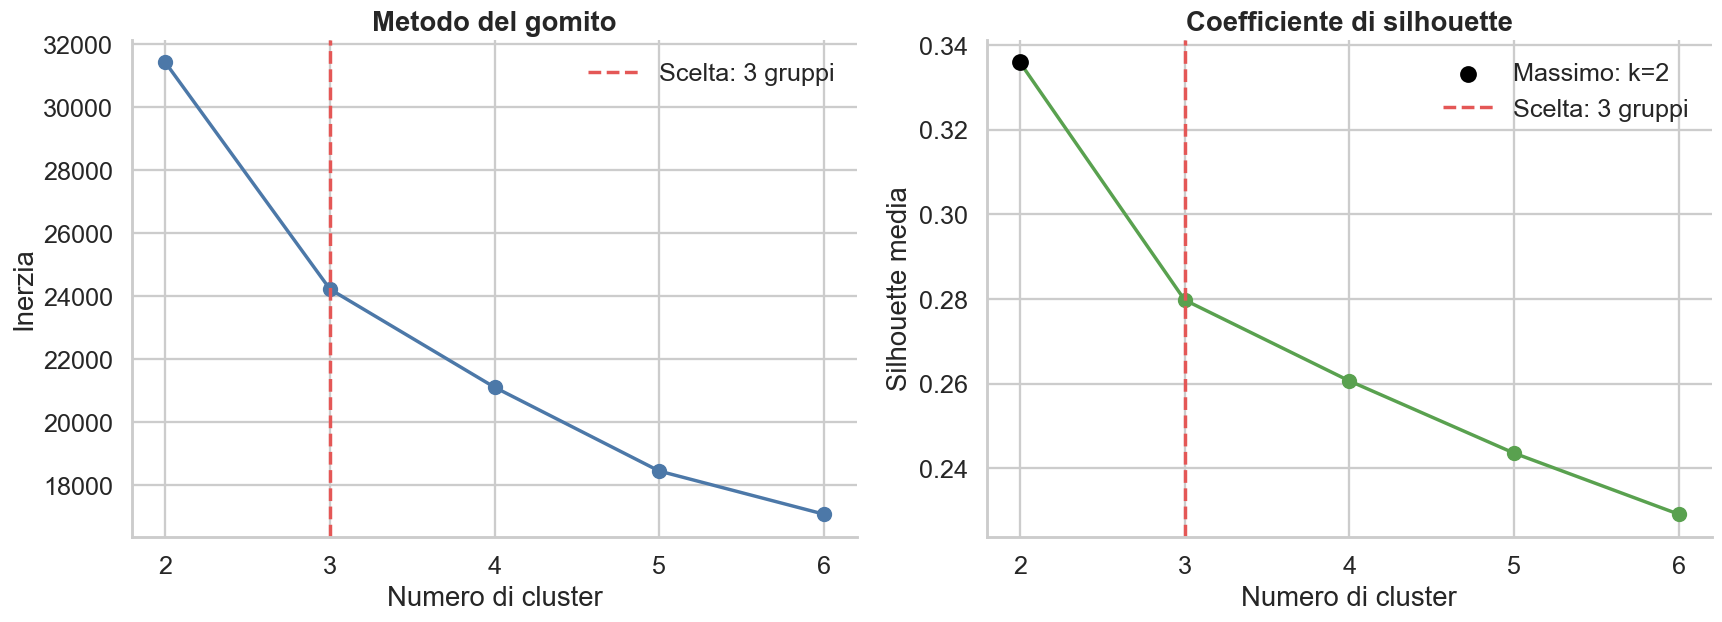

La silhouette favorisce due gruppi. Tre gruppi vengono mantenuti per distinguere
un profilo di manovra intermedio fra giocatori offensivi e difensivi.


In [5]:
k_values = range(2, 7)
selection_rows = []
models = {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels = model.fit_predict(X_pca)
    models[k] = model
    counts = np.bincount(labels)
    selection_rows.append({
        'Numero di cluster': k,
        'Inerzia': model.inertia_,
        'Silhouette': silhouette_score(X_pca, labels),
        'Cluster più piccolo': counts.min(),
        'Cluster più grande': counts.max(),
    })

selection_table = pd.DataFrame(selection_rows).set_index('Numero di cluster')
display(selection_table.style.format({
    'Inerzia': '{:.1f}',
    'Silhouette': '{:.4f}',
    'Cluster più piccolo': '{:.0f}',
    'Cluster più grande': '{:.0f}',
}).highlight_max(subset=['Silhouette'], color='#c7e9c0'))

CHOSEN_K = 3

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].plot(selection_table.index, selection_table['Inerzia'], marker='o', color='#4c78a8')
axes[0].axvline(CHOSEN_K, color='#e45756', linestyle='--', label='Scelta: 3 gruppi')
axes[0].set_title('Metodo del gomito')
axes[0].set_xlabel('Numero di cluster')
axes[0].set_ylabel('Inerzia')
axes[0].set_xticks(list(k_values))
axes[0].legend()

axes[1].plot(selection_table.index, selection_table['Silhouette'], marker='o', color='#59a14f')
best_k = int(selection_table['Silhouette'].idxmax())
axes[1].scatter([best_k], [selection_table.loc[best_k, 'Silhouette']],
                color='black', s=90, zorder=5, label=f'Massimo: k={best_k}')
axes[1].axvline(CHOSEN_K, color='#e45756', linestyle='--', label='Scelta: 3 gruppi')
axes[1].set_title('Coefficiente di silhouette')
axes[1].set_xlabel('Numero di cluster')
axes[1].set_ylabel('Silhouette media')
axes[1].set_xticks(list(k_values))
axes[1].legend()

fig.tight_layout()
fig.savefig(FIG_DIR / '03_scelta_numero_cluster.png', dpi=300, bbox_inches='tight')
plt.show()

print('La silhouette favorisce due gruppi. Tre gruppi vengono mantenuti per distinguere')
print('un profilo di manovra intermedio fra giocatori offensivi e difensivi.')

## 4. Soluzione a tre gruppi

I nomi non vengono assegnati in anticipo. Sono determinati dopo aver osservato le statistiche medie:

- il gruppo con il valore `SHO` più elevato viene definito offensivo;
- il gruppo con `DEF` più elevato viene definito difensivo;
- il gruppo rimanente viene definito di manovra.

In [6]:
kmeans = models[CHOSEN_K]
cluster_ids = kmeans.labels_

df_clustered = df_top.copy()
df_clustered['Cluster_ID'] = cluster_ids

face_stats = ['PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY']
cluster_means = df_clustered.groupby('Cluster_ID')[face_stats].mean()

offensive_id = int(cluster_means['SHO'].idxmax())
defensive_id = int(cluster_means['DEF'].idxmax())
manovra_id = int(next(i for i in cluster_means.index if i not in {offensive_id, defensive_id}))

cluster_names = {
    offensive_id: 'Profilo offensivo',
    manovra_id: 'Profilo di manovra',
    defensive_id: 'Profilo difensivo',
}
df_clustered['Profilo'] = df_clustered['Cluster_ID'].map(cluster_names)
pca_df['Cluster_ID'] = cluster_ids
pca_df['Profilo'] = df_clustered['Profilo'].to_numpy()

profile_order = ['Profilo offensivo', 'Profilo di manovra', 'Profilo difensivo']
profile_colors = {
    'Profilo offensivo': '#e45756',
    'Profilo di manovra': '#4c78a8',
    'Profilo difensivo': '#59a14f',
}

summary = (
    df_clustered.groupby('Profilo')
    .agg(Giocatori=('Name', 'size'), OVR_medio=('OVR', 'mean'))
    .reindex(profile_order)
)
display(summary.style.format({'OVR_medio': '{:.2f}'}))

means_named = (
    df_clustered.groupby('Profilo')[face_stats]
    .mean()
    .reindex(profile_order)
)
display(means_named.style.format('{:.1f}'))

,Giocatori,OVR_medio
Profilo,,
Profilo offensivo,733,78.57
Profilo di manovra,871,78.96
Profilo difensivo,482,77.80


,PAC,SHO,PAS,DRI,DEF,PHY
Profilo,,,,,,
Profilo offensivo,79.4,76.2,71.5,79.0,41.2,68.8
Profilo di manovra,71.5,67.8,75.7,77.5,72.1,73.4
Profilo difensivo,65.1,45.1,62.7,65.2,78.2,76.9


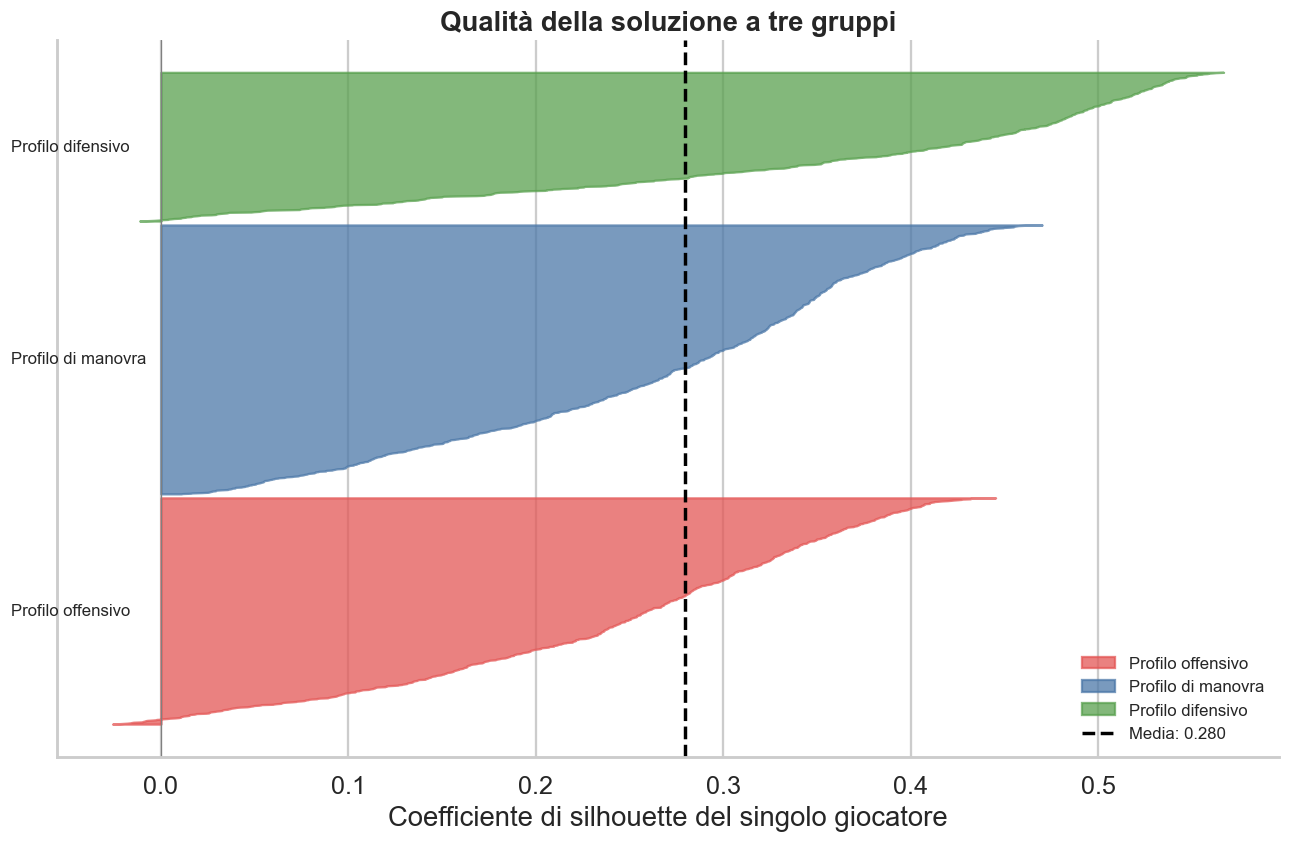

In [7]:
sample_values = silhouette_samples(X_pca, cluster_ids)
silhouette_avg = silhouette_score(X_pca, cluster_ids)

fig, ax = plt.subplots(figsize=(12, 8))
y_lower = 10

for profile in profile_order:
    cluster_id = next(key for key, value in cluster_names.items() if value == profile)
    values = np.sort(sample_values[cluster_ids == cluster_id])
    y_upper = y_lower + len(values)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, values,
                     color=profile_colors[profile], alpha=0.75, label=profile)
    ax.text(-0.08, y_lower + len(values) / 2, profile, va='center', fontsize=11)
    y_lower = y_upper + 12

ax.axvline(silhouette_avg, color='black', linestyle='--',
           label=f'Media: {silhouette_avg:.3f}')
ax.axvline(0, color='grey', linewidth=0.8)
ax.set_title('Qualità della soluzione a tre gruppi')
ax.set_xlabel('Coefficiente di silhouette del singolo giocatore')
ax.set_ylabel('')
ax.set_yticks([])
ax.legend(loc='lower right', fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / '04_silhouette_tre_cluster.png', dpi=300, bbox_inches='tight')
plt.show()

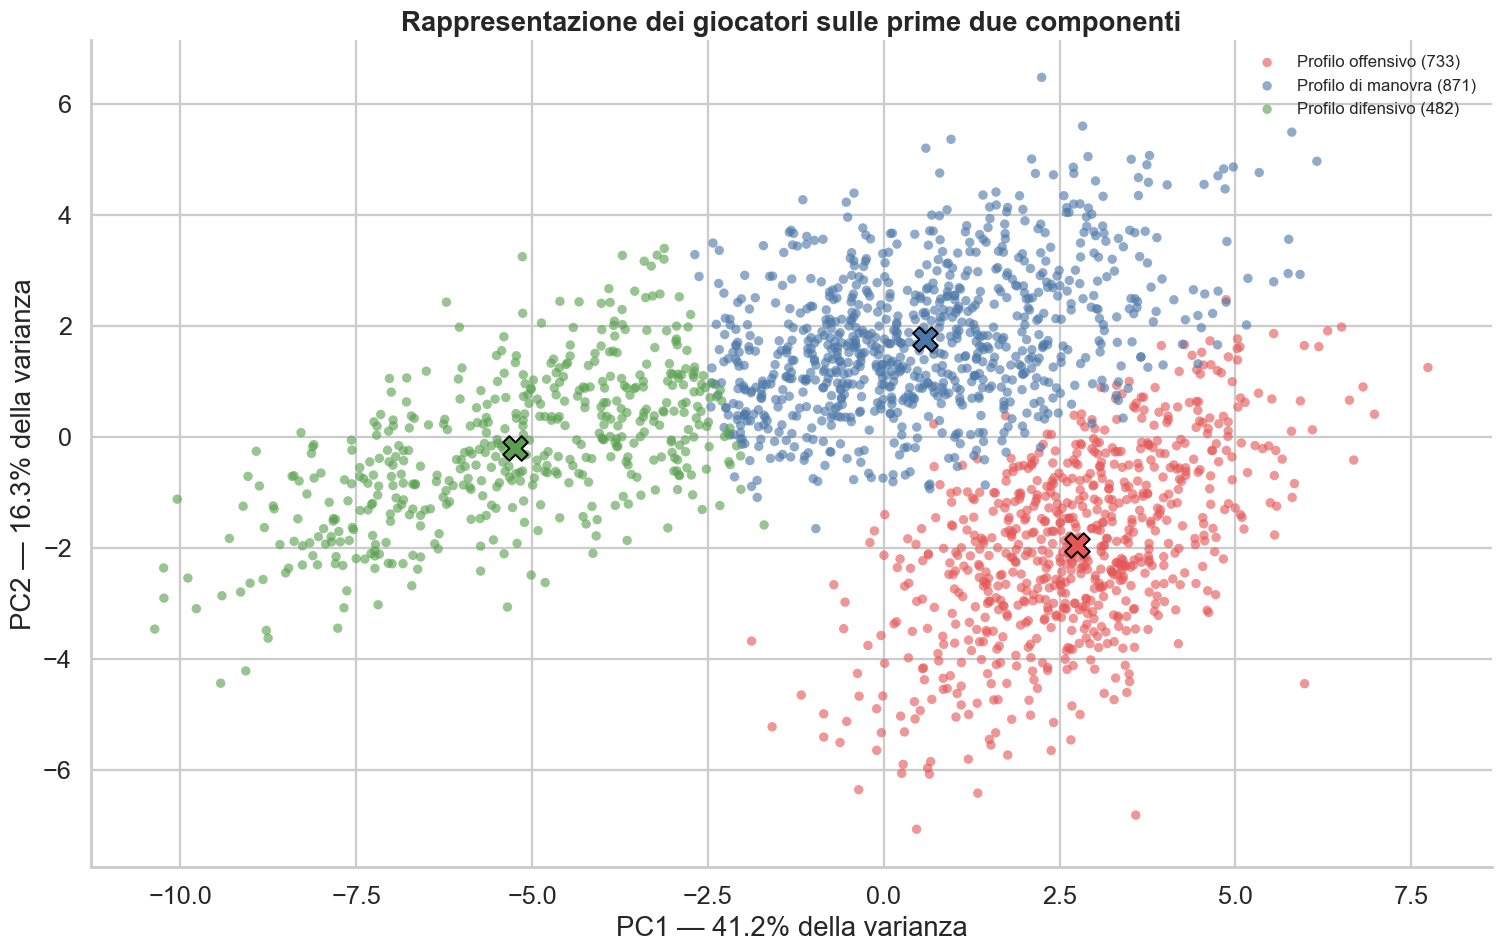

In [8]:
fig, ax = plt.subplots(figsize=(14, 9))

for profile in profile_order:
    mask = pca_df['Profilo'] == profile
    ax.scatter(
        pca_df.loc[mask, 'PC1'],
        pca_df.loc[mask, 'PC2'],
        s=38,
        alpha=0.62,
        color=profile_colors[profile],
        label=f'{profile} ({mask.sum()})',
        edgecolors='none',
    )

for cluster_id, center in enumerate(kmeans.cluster_centers_):
    profile = cluster_names[cluster_id]
    ax.scatter(center[0], center[1], marker='X', s=260,
               color=profile_colors[profile], edgecolor='black', linewidth=1.3)

ax.set_title('Rappresentazione dei giocatori sulle prime due componenti')
ax.set_xlabel(f'PC1 — {pca.explained_variance_ratio_[0] * 100:.1f}% della varianza')
ax.set_ylabel(f'PC2 — {pca.explained_variance_ratio_[1] * 100:.1f}% della varianza')
ax.legend(loc='best', fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / '05_mappa_profili.png', dpi=300, bbox_inches='tight')
plt.show()

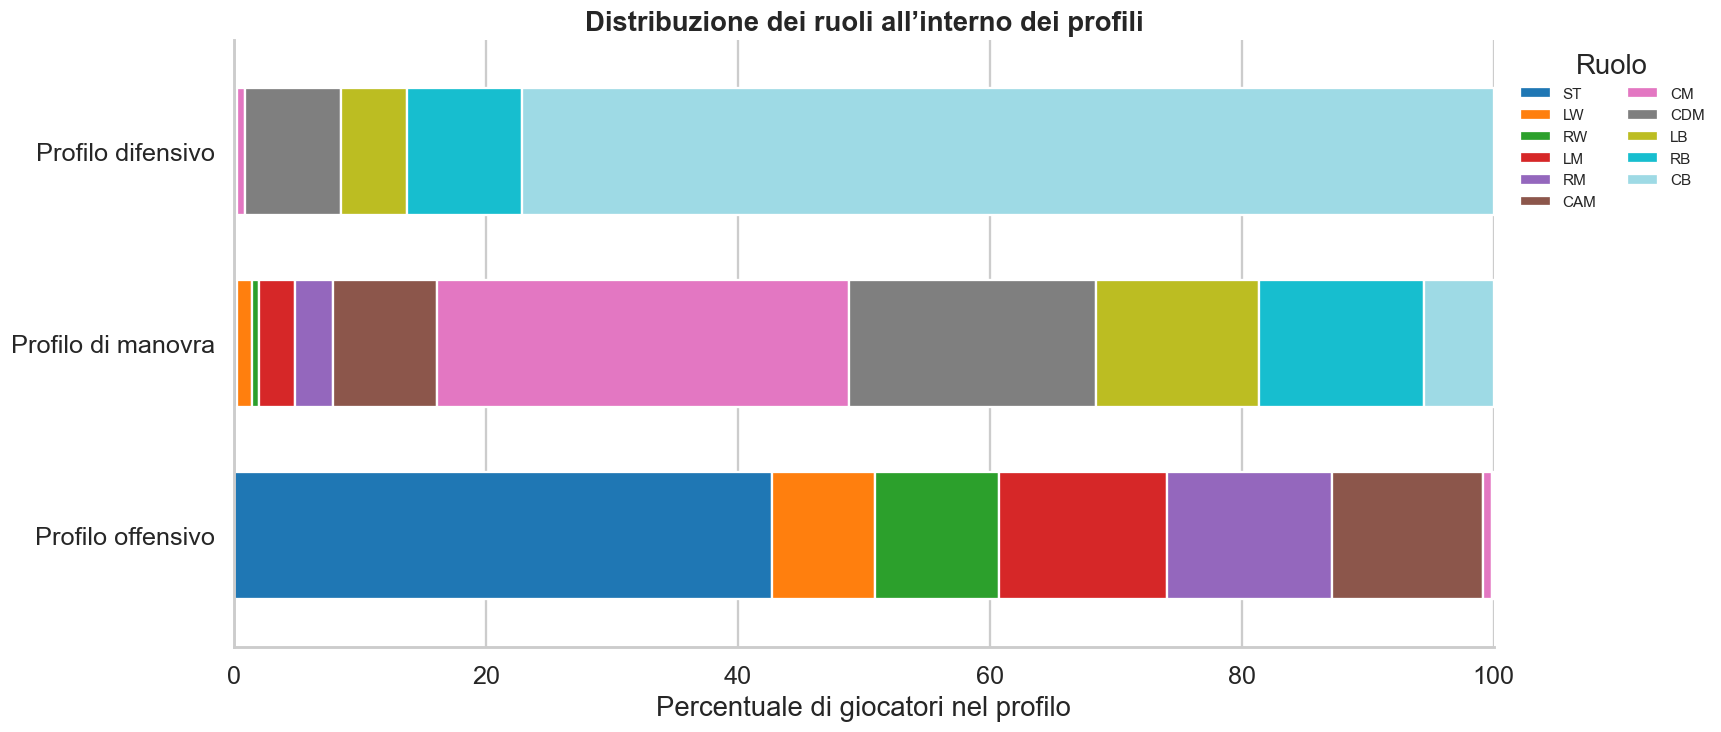

Position,ST,LW,RW,LM,RM,CAM,CM,CDM,LB,RB,CB
Profilo,,,,,,,,,,,
Profilo offensivo,42.7%,8.2%,9.8%,13.4%,13.1%,12.0%,0.7%,0.0%,0.0%,0.1%,0.0%
Profilo di manovra,0.2%,1.1%,0.6%,2.9%,3.0%,8.3%,32.7%,19.6%,13.0%,13.1%,5.5%
Profilo difensivo,0.2%,0.0%,0.0%,0.0%,0.0%,0.0%,0.6%,7.7%,5.2%,9.1%,77.2%


In [9]:
role_distribution = pd.crosstab(
    df_clustered['Profilo'],
    df_clustered['Position'],
    normalize='index',
).mul(100).reindex(profile_order)

position_order = ['ST', 'LW', 'RW', 'LM', 'RM', 'CAM', 'CM', 'CDM', 'LB', 'RB', 'CB']
position_order = [position for position in position_order if position in role_distribution.columns]
role_distribution = role_distribution[position_order]

ax = role_distribution.plot(
    kind='barh',
    stacked=True,
    figsize=(16, 7),
    colormap='tab20',
    width=0.66,
)
ax.set_title('Distribuzione dei ruoli all’interno dei profili')
ax.set_xlabel('Percentuale di giocatori nel profilo')
ax.set_ylabel('')
ax.set_xlim(0, 100)
ax.legend(title='Ruolo', bbox_to_anchor=(1.01, 1), loc='upper left', ncol=2, fontsize=10)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / '06_distribuzione_ruoli.png', dpi=300, bbox_inches='tight')
plt.show()

display(role_distribution.style.format('{:.1f}%'))

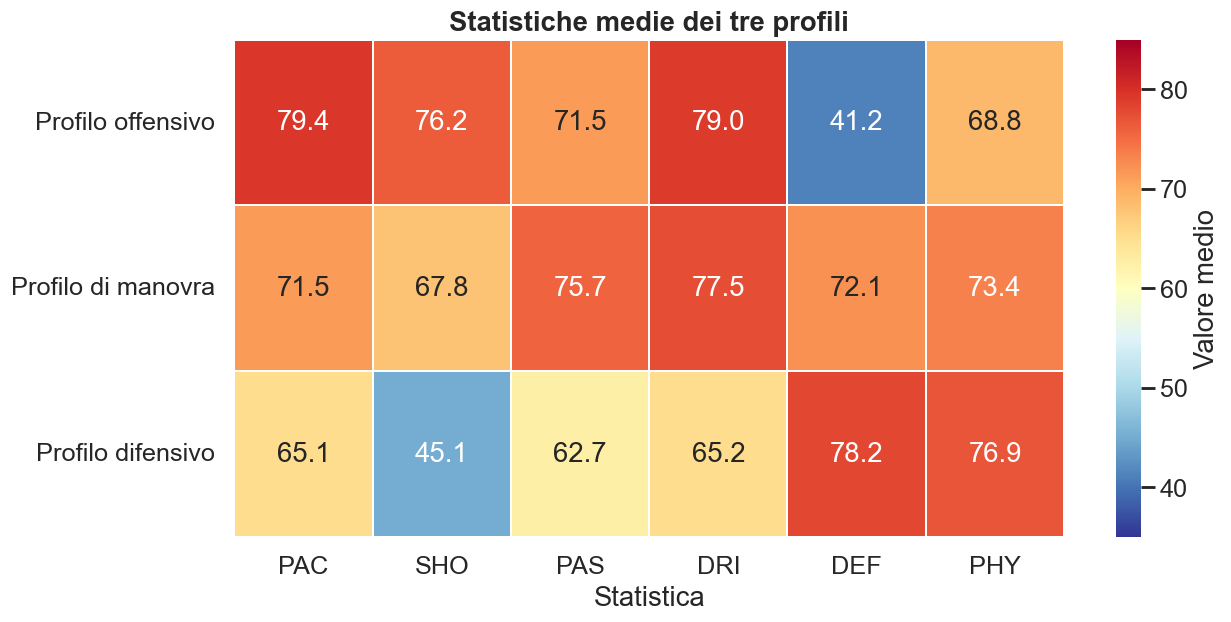

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(
    means_named,
    annot=True,
    fmt='.1f',
    cmap='RdYlBu_r',
    vmin=35,
    vmax=85,
    linewidths=1,
    cbar_kws={'label': 'Valore medio'},
    ax=ax,
)
ax.set_title('Statistiche medie dei tre profili')
ax.set_xlabel('Statistica')
ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
fig.tight_layout()
fig.savefig(FIG_DIR / '07_profili_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

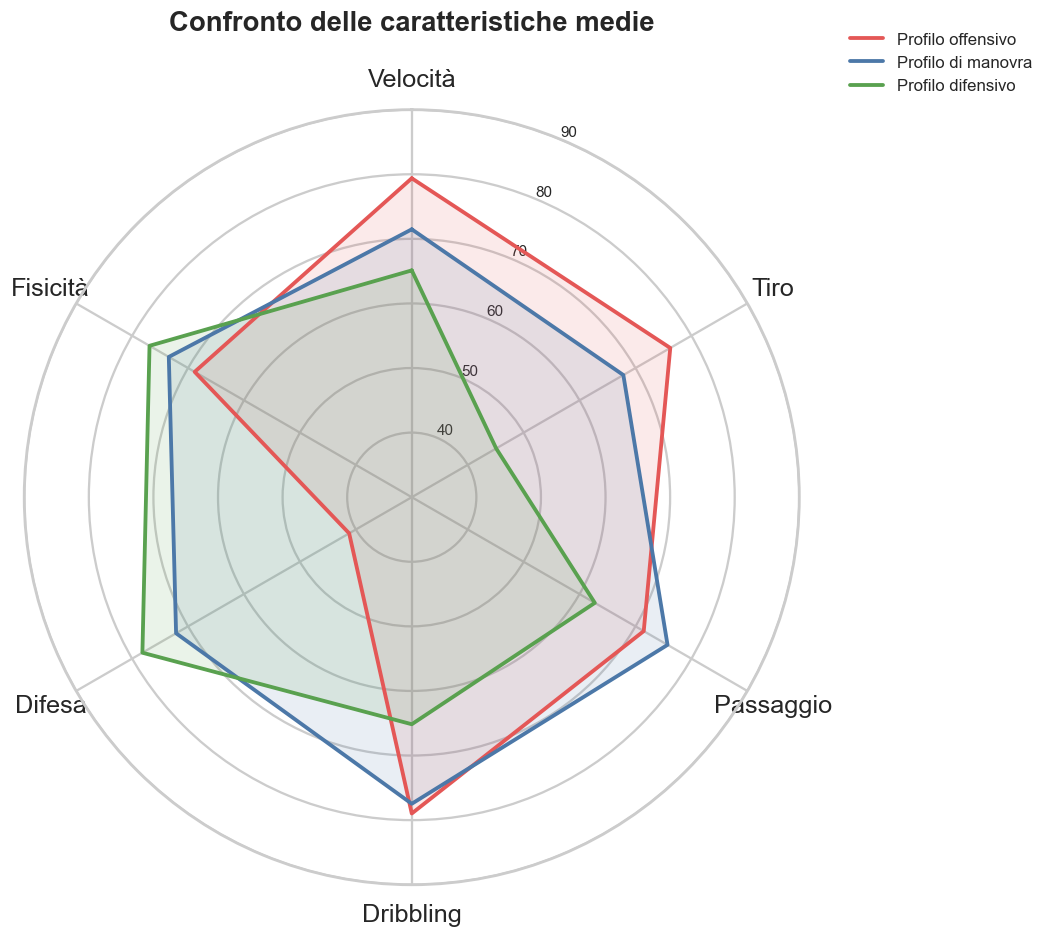

In [11]:
radar_labels = ['Velocità', 'Tiro', 'Passaggio', 'Dribbling', 'Difesa', 'Fisicità']
angles = np.linspace(0, 2 * np.pi, len(face_stats), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'polar': True})

for profile in profile_order:
    values = means_named.loc[profile].tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2.5, color=profile_colors[profile], label=profile)
    ax.fill(angles, values, color=profile_colors[profile], alpha=0.12)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_labels)
ax.set_ylim(30, 90)
ax.set_yticks([40, 50, 60, 70, 80, 90])
ax.set_yticklabels(['40', '50', '60', '70', '80', '90'], fontsize=10)
ax.set_title('Confronto delle caratteristiche medie', pad=25)
ax.legend(loc='upper right', bbox_to_anchor=(1.32, 1.12), fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / '08_profili_radar.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Giocatori rappresentativi

Per ogni profilo vengono mostrati i giocatori più vicini al centro del rispettivo cluster, anziché esempi estratti casualmente.

In [12]:
distances = np.linalg.norm(X_pca - kmeans.cluster_centers_[cluster_ids], axis=1)
df_clustered['Distanza_dal_centro'] = distances

representative_tables = []
for profile in profile_order:
    examples = (
        df_clustered.loc[df_clustered['Profilo'] == profile]
        .nsmallest(6, 'Distanza_dal_centro')
        [['Name', 'Position', 'OVR', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY']]
        .copy()
    )
    examples.insert(0, 'Profilo', profile)
    representative_tables.append(examples)

representative_players = pd.concat(representative_tables, ignore_index=True)
display(representative_players)

,Profilo,Name,Position,OVR,PAC,SHO,PAS,DRI,DEF,PHY
0,Profilo offensivo,Mélissa Gomes,ST,76,77,76,71,79,43,67
1,Profilo offensivo,Lee Geum Min,ST,78,80,77,72,78,37,68
2,Profilo offensivo,Georges Mikautadze,ST,77,81,78,72,80,40,71
3,Profilo offensivo,Lisa Kolb,RW,78,76,71,77,80,46,72
4,Profilo offensivo,Fabio Borini,LW,75,72,75,72,76,46,71
5,Profilo offensivo,Sandra Starke,ST,77,82,74,67,79,48,69
6,Profilo di manovra,Farès Chaïbi,CAM,77,75,70,77,77,68,73
7,Profilo di manovra,Suat Serdar,CM,77,68,71,73,79,73,76
8,Profilo di manovra,Nicolas Raskin,CM,75,69,63,73,75,72,75
9,Profilo di manovra,Ben Chilwell,LB,79,76,60,78,77,75,72


## 6. Approfondimento sui centrocampisti

Per verificare se le differenze tra macro-ruoli nascondano strutture più specifiche, il clustering viene ripetuto sui soli centrocampisti con `OVR >= 75`: `CAM`, `CM`, `CDM`, `LM` e `RM`. Standardizzazione e PCA vengono ricalcolate sul sottoinsieme, in modo che le componenti descrivano le differenze interne al reparto. L'obiettivo non è riprodurre necessariamente le posizioni nominali, ma verificare se emergano profili funzionali interpretabili.

Centrocampisti analizzati: 906
Componenti PCA utilizzate: 8
Varianza spiegata: 81.60%


,Inerzia,Silhouette,Cluster più piccolo,Cluster più grande
Numero di cluster,,,,
2,16176.0,0.2212,443,463
3,12617.3,0.2386,288,316
4,11412.5,0.2049,92,327
5,10607.8,0.1809,86,245
6,9852.4,0.1735,88,225


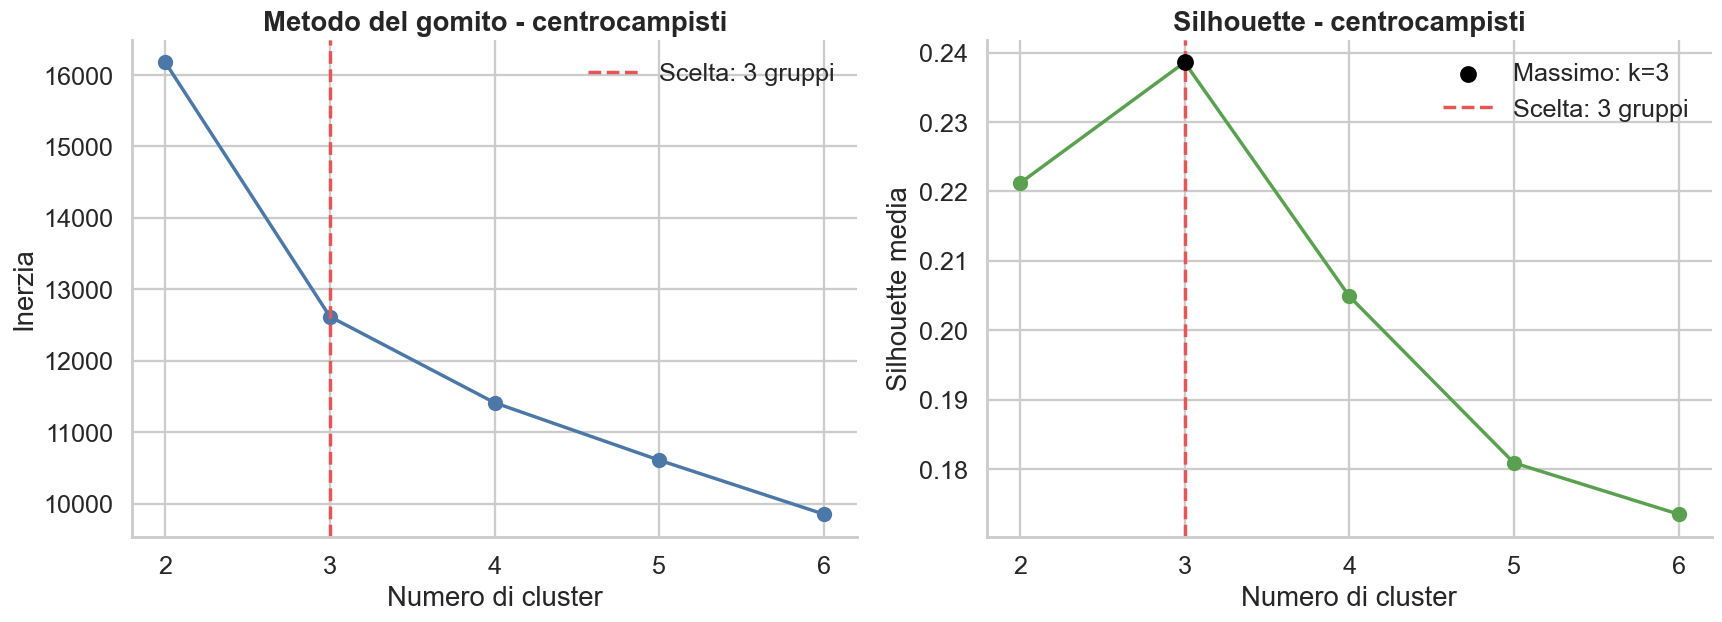

In [13]:
MIDFIELD_POSITIONS = ['CAM', 'CM', 'CDM', 'LM', 'RM']
df_midfield = (
    df_top.loc[df_top['Position'].isin(MIDFIELD_POSITIONS)]
    .copy()
    .reset_index(drop=True)
)

X_midfield = df_midfield[technical_features].copy()
midfield_scaler = StandardScaler()
X_midfield_scaled = midfield_scaler.fit_transform(X_midfield)

midfield_pca_full = PCA().fit(X_midfield_scaled)
midfield_cumulative = np.cumsum(midfield_pca_full.explained_variance_ratio_)
MIDFIELD_COMPONENTS = int(np.argmax(midfield_cumulative >= 0.80) + 1)
midfield_pca = PCA(n_components=MIDFIELD_COMPONENTS)
X_midfield_pca = midfield_pca.fit_transform(X_midfield_scaled)

midfield_rows = []
midfield_models = {}
for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels = model.fit_predict(X_midfield_pca)
    midfield_models[k] = model
    counts = np.bincount(labels)
    midfield_rows.append({
        'Numero di cluster': k,
        'Inerzia': model.inertia_,
        'Silhouette': silhouette_score(X_midfield_pca, labels),
        'Cluster più piccolo': counts.min(),
        'Cluster più grande': counts.max(),
    })

midfield_selection = (
    pd.DataFrame(midfield_rows).set_index('Numero di cluster')
)
MIDFIELD_K = 3

print(f'Centrocampisti analizzati: {len(df_midfield):,}')
print(f'Componenti PCA utilizzate: {MIDFIELD_COMPONENTS}')
print(
    f'Varianza spiegata: '
    f'{midfield_pca.explained_variance_ratio_.sum() * 100:.2f}%'
)
display(midfield_selection.style.format({
    'Inerzia': '{:.1f}',
    'Silhouette': '{:.4f}',
    'Cluster più piccolo': '{:.0f}',
    'Cluster più grande': '{:.0f}',
}).highlight_max(subset=['Silhouette'], color='#c7e9c0'))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].plot(
    midfield_selection.index, midfield_selection['Inerzia'],
    marker='o', color='#4c78a8'
)
axes[0].axvline(
    MIDFIELD_K, color='#e45756', linestyle='--',
    label='Scelta: 3 gruppi'
)
axes[0].set_title('Metodo del gomito - centrocampisti')
axes[0].set_xlabel('Numero di cluster')
axes[0].set_ylabel('Inerzia')
axes[0].set_xticks(midfield_selection.index)
axes[0].legend()

axes[1].plot(
    midfield_selection.index, midfield_selection['Silhouette'],
    marker='o', color='#59a14f'
)
best_midfield_k = int(midfield_selection['Silhouette'].idxmax())
axes[1].scatter(
    [best_midfield_k],
    [midfield_selection.loc[best_midfield_k, 'Silhouette']],
    color='black', s=90, zorder=5,
    label=f'Massimo: k={best_midfield_k}'
)
axes[1].axvline(
    MIDFIELD_K, color='#e45756', linestyle='--',
    label='Scelta: 3 gruppi'
)
axes[1].set_title('Silhouette - centrocampisti')
axes[1].set_xlabel('Numero di cluster')
axes[1].set_ylabel('Silhouette media')
axes[1].set_xticks(midfield_selection.index)
axes[1].legend()

fig.tight_layout()
fig.savefig(
    FIG_DIR / '16_scelta_cluster_centrocampisti.png',
    dpi=300, bbox_inches='tight'
)
plt.show()

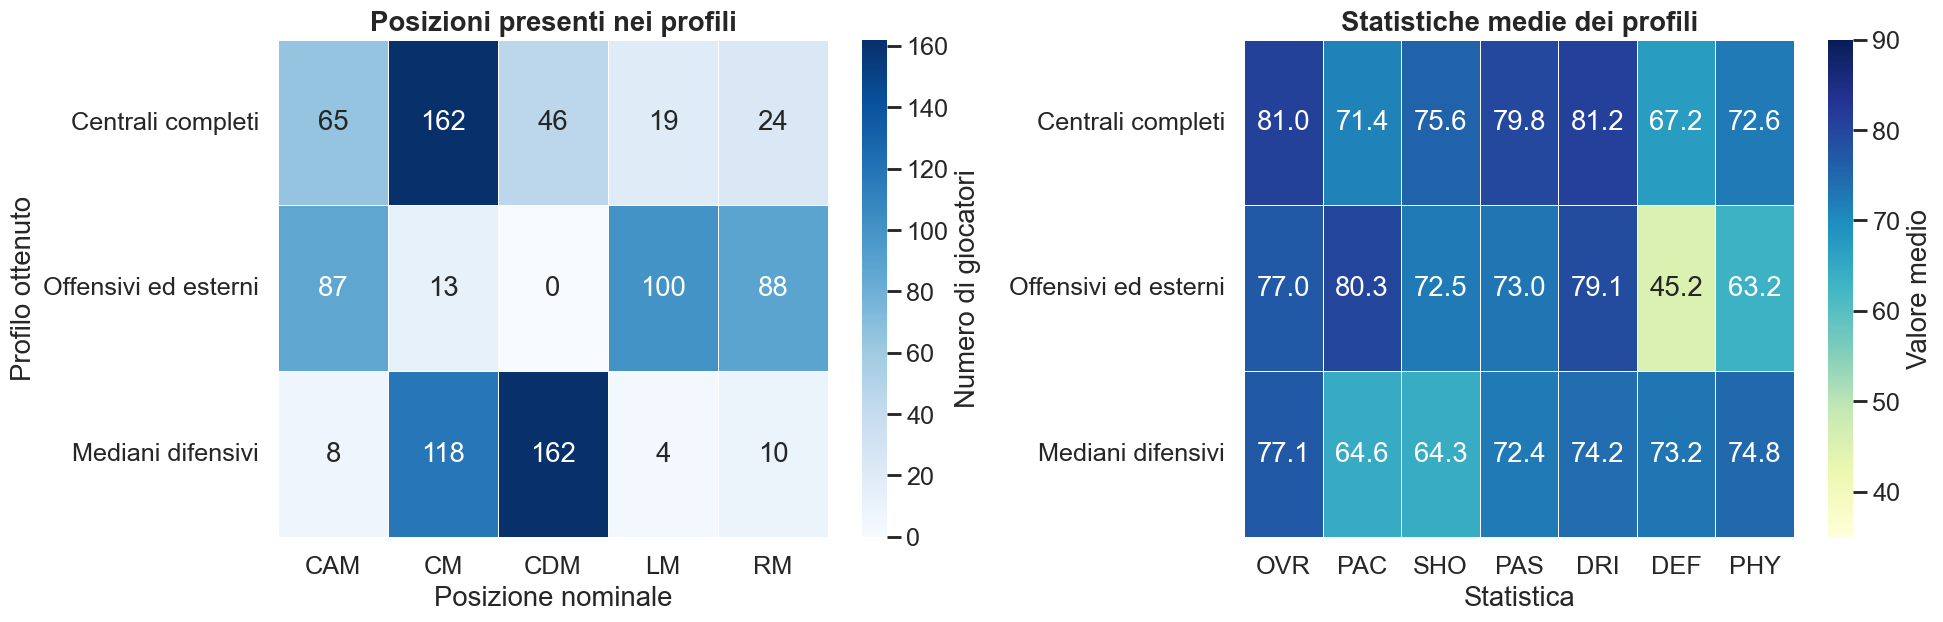

,Giocatori
Profilo,
Centrali completi,316
Offensivi ed esterni,288
Mediani difensivi,302


Position,CAM,CM,CDM,LM,RM
Profilo,,,,,
Centrali completi,65,162,46,19,24
Offensivi ed esterni,87,13,0,100,88
Mediani difensivi,8,118,162,4,10


,OVR,PAC,SHO,PAS,DRI,DEF,PHY
Profilo,,,,,,,
Centrali completi,81.0,71.4,75.6,79.8,81.2,67.2,72.6
Offensivi ed esterni,77.0,80.3,72.5,73.0,79.1,45.2,63.2
Mediani difensivi,77.1,64.6,64.3,72.4,74.2,73.2,74.8


In [14]:
midfield_model = midfield_models[MIDFIELD_K]
df_midfield['Cluster'] = midfield_model.labels_

midfield_summary_features = ['OVR', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY']
midfield_cluster_means = (
    df_midfield.groupby('Cluster')[midfield_summary_features].mean()
)

defensive_cluster = int(midfield_cluster_means['DEF'].idxmax())
remaining_clusters = [
    cluster for cluster in midfield_cluster_means.index
    if cluster != defensive_cluster
]
wide_cluster = int(
    midfield_cluster_means.loc[remaining_clusters, 'PAC'].idxmax()
)
central_cluster = int(
    next(
        cluster for cluster in remaining_clusters
        if cluster != wide_cluster
    )
)

midfield_profile_map = {
    central_cluster: 'Centrali completi',
    wide_cluster: 'Offensivi ed esterni',
    defensive_cluster: 'Mediani difensivi',
}
midfield_profile_order = [
    'Centrali completi',
    'Offensivi ed esterni',
    'Mediani difensivi',
]
df_midfield['Profilo'] = df_midfield['Cluster'].map(midfield_profile_map)

midfield_position_table = pd.crosstab(
    df_midfield['Profilo'], df_midfield['Position']
).reindex(index=midfield_profile_order, columns=MIDFIELD_POSITIONS, fill_value=0)
midfield_profile_means = (
    df_midfield.groupby('Profilo')[midfield_summary_features]
    .mean()
    .reindex(midfield_profile_order)
)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.heatmap(
    midfield_position_table, annot=True, fmt='d', cmap='Blues',
    linewidths=0.5, cbar_kws={'label': 'Numero di giocatori'},
    ax=axes[0]
)
axes[0].set_title('Posizioni presenti nei profili')
axes[0].set_xlabel('Posizione nominale')
axes[0].set_ylabel('Profilo ottenuto')
axes[0].tick_params(axis='x', rotation=0)
axes[0].tick_params(axis='y', rotation=0)

sns.heatmap(
    midfield_profile_means, annot=True, fmt='.1f', cmap='YlGnBu',
    vmin=35, vmax=90, linewidths=0.5,
    cbar_kws={'label': 'Valore medio'}, ax=axes[1]
)
axes[1].set_title('Statistiche medie dei profili')
axes[1].set_xlabel('Statistica')
axes[1].set_ylabel('')
axes[1].tick_params(axis='x', rotation=0)
axes[1].tick_params(axis='y', rotation=0)

fig.tight_layout()
fig.savefig(
    FIG_DIR / '17_profili_centrocampisti.png',
    dpi=300, bbox_inches='tight'
)
plt.show()

midfield_profile_sizes = (
    df_midfield['Profilo'].value_counts().reindex(midfield_profile_order)
)
display(midfield_profile_sizes.rename('Giocatori').to_frame())
display(midfield_position_table)
display(midfield_profile_means.style.format('{:.1f}'))

### Interpretazione

La soluzione a tre gruppi presenta la silhouette più alta tra quelle valutate, circa **0,239**, e produce gruppi equilibrati di 316, 288 e 302 giocatori. Il primo profilo raccoglie soprattutto centrocampisti centrali tecnici e completi; il secondo comprende prevalentemente esterni e trequartisti, caratterizzati da maggiore velocità e minore propensione difensiva; il terzo riunisce soprattutto mediani e centrocampisti con valori più elevati di difesa e fisicità.

I cluster non coincidono perfettamente con le posizioni nominali. Questo risultato suggerisce che le etichette `CAM`, `CM`, `CDM`, `LM` e `RM` descrivono ruoli parzialmente sovrapposti, mentre il clustering evidenzia tre profili funzionali più generali. La separazione rimane moderata e deve quindi essere interpretata come una sintesi dei diversi stili, non come una classificazione rigida.

### 6.1 Sintesi

- Sei componenti principali conservano oltre l'80% dell'informazione contenuta nelle 29 statistiche tecniche.
- La silhouette favorisce una divisione più generale in due gruppi, che massimizza la separazione statistica.
- La soluzione a tre gruppi ha una silhouette inferiore, ma consente di distinguere un profilo intermedio di manovra ed è più utile per l'interpretazione calcistica.
- I giocatori non formano categorie perfettamente separate: i profili rappresentano zone di un insieme continuo di caratteristiche tattiche.
- Limitando l'analisi ai centrocampisti, tre gruppi equilibrati distinguono profili centrali completi, offensivi ed esterni e mediani difensivi, pur mantenendo una separazione moderata.

In [15]:
print('RISULTATI PRINCIPALI')
print('-' * 60)
print(f'Giocatori analizzati: {len(df_clustered):,}')
print(f'Componenti PCA utilizzate: {N_COMPONENTS}')
print(f'Varianza spiegata: {pca.explained_variance_ratio_.sum() * 100:.2f}%')
print(f'Silhouette k=2: {selection_table.loc[2, "Silhouette"]:.4f}')
print(f'Silhouette k=3: {selection_table.loc[3, "Silhouette"]:.4f}')
print('\nDimensione dei profili:')
for profile in profile_order:
    count = int((df_clustered['Profilo'] == profile).sum())
    print(f'- {profile}: {count} giocatori')

print('\nAPPROFONDIMENTO SUI CENTROCAMPISTI')
print('-' * 60)
print(f'Centrocampisti analizzati: {len(df_midfield):,}')
print(f'Componenti PCA utilizzate: {MIDFIELD_COMPONENTS}')
print(
    f'Silhouette k=3: '
    f'{midfield_selection.loc[MIDFIELD_K, "Silhouette"]:.4f}'
)
for profile, count in midfield_profile_sizes.items():
    print(f'- {profile}: {count} giocatori')

RISULTATI PRINCIPALI
------------------------------------------------------------
Giocatori analizzati: 2,086
Componenti PCA utilizzate: 6
Varianza spiegata: 81.32%
Silhouette k=2: 0.3359
Silhouette k=3: 0.2798

Dimensione dei profili:
- Profilo offensivo: 733 giocatori
- Profilo di manovra: 871 giocatori
- Profilo difensivo: 482 giocatori

APPROFONDIMENTO SUI CENTROCAMPISTI
------------------------------------------------------------
Centrocampisti analizzati: 906
Componenti PCA utilizzate: 8
Silhouette k=3: 0.2386
- Centrali completi: 316 giocatori
- Offensivi ed esterni: 288 giocatori
- Mediani difensivi: 302 giocatori


## 7. Clustering gerarchico

Il metodo gerarchico agglomerativo costruisce prima l'intera struttura ad albero, senza richiedere un numero di cluster. Ogni giocatore parte come gruppo separato e le fusioni proseguono fino a ottenere un unico gruppo.

Viene utilizzato il metodo di Ward sulle stesse sei componenti principali impiegate da K-Means. In questo modo ogni fusione cerca di limitare l'aumento della variabilità interna. Il numero di gruppi viene valutato soltanto dopo la costruzione della gerarchia.

In [16]:
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

# La matrice contiene tutte le fusioni della gerarchia, dalla prima all'ultima.
linkage_matrix = linkage(X_pca, method='ward', metric='euclidean')

print(f'Giocatori inseriti nella gerarchia: {len(X_pca):,}')
print(f'Fusioni complessive: {len(linkage_matrix):,}')
print('Il numero di cluster non è stato specificato durante questa fase.')

Giocatori inseriti nella gerarchia: 2,086
Fusioni complessive: 2,085
Il numero di cluster non è stato specificato durante questa fase.


### 7.1 Dendrogramma

Il dendrogramma completo contiene più di duemila foglie e risulterebbe illeggibile. La versione seguente mostra le ultime 35 ramificazioni; i numeri tra parentesi indicano quanti giocatori sono raccolti in ciascun ramo condensato. L'altezza delle fusioni rappresenta quanto erano diversi i gruppi che sono stati uniti.

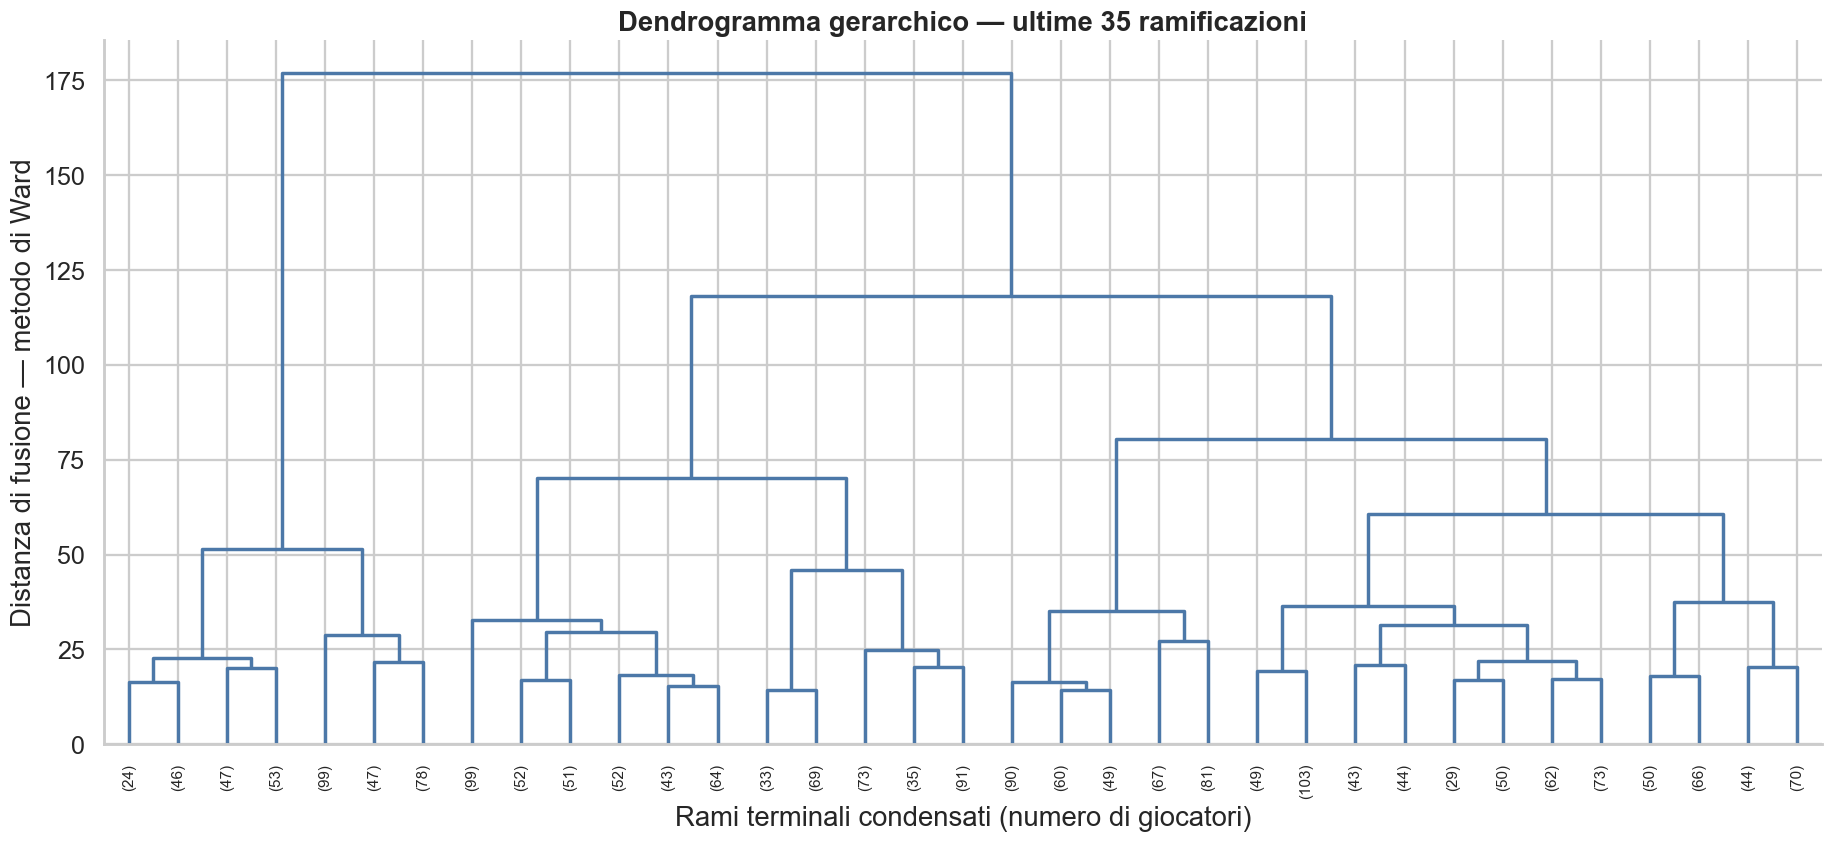

In [17]:
fig, ax = plt.subplots(figsize=(17, 8))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=35,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=10,
    color_threshold=0,
    above_threshold_color='#4c78a8',
    ax=ax,
)
ax.set_title('Dendrogramma gerarchico — ultime 35 ramificazioni')
ax.set_xlabel('Rami terminali condensati (numero di giocatori)')
ax.set_ylabel('Distanza di fusione — metodo di Ward')
fig.tight_layout()
fig.savefig(FIG_DIR / '09_dendrogramma_gerarchico.png', dpi=300, bbox_inches='tight')
plt.show()

### 7.2 Distanze delle fusioni finali

Un forte aumento della distanza significa che l'algoritmo sta unendo gruppi molto diversi. Le fusioni finali sono quindi utili per individuare possibili livelli di taglio dell'albero, senza imporli prima della costruzione.

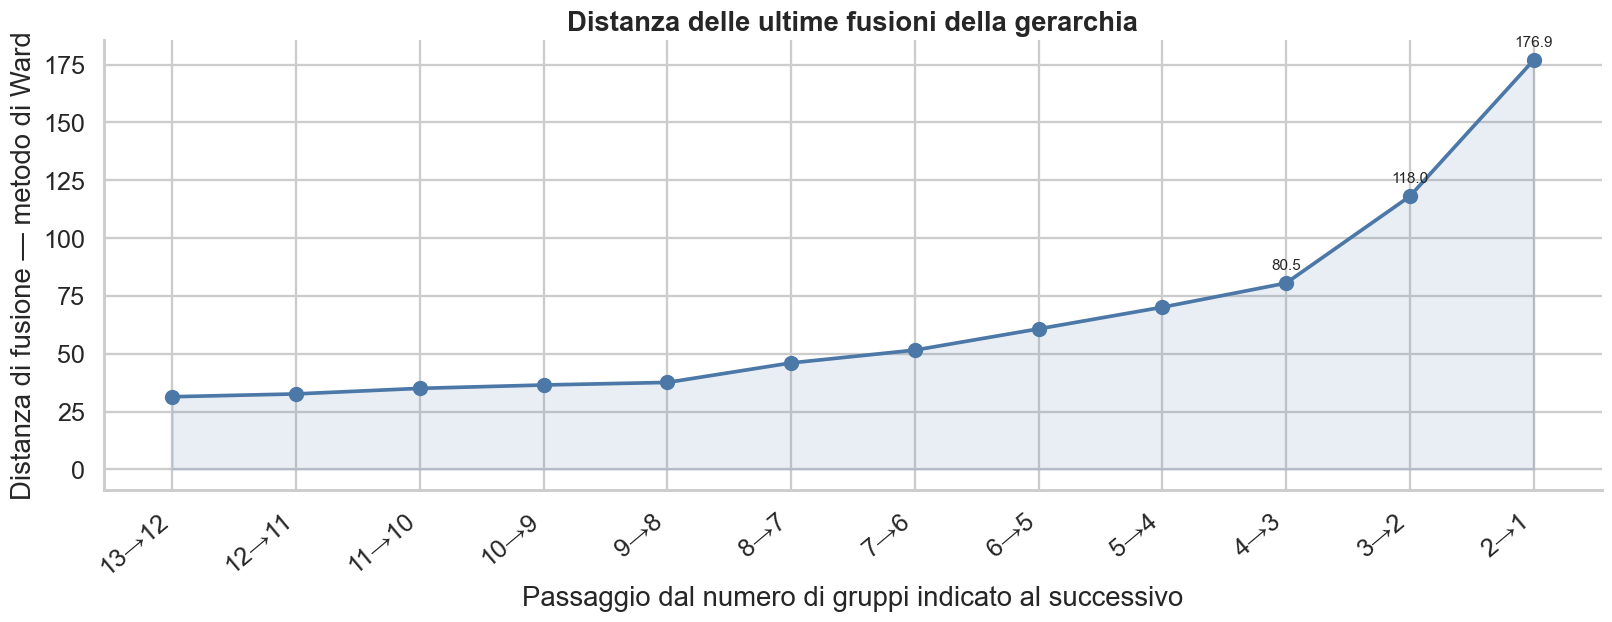

In [18]:
N_LAST_MERGES = 12
last_rows = linkage_matrix[-N_LAST_MERGES:]
row_indices = np.arange(len(linkage_matrix) - N_LAST_MERGES, len(linkage_matrix))
groups_before = len(X_pca) - row_indices
transition_labels = [f'{before}→{before - 1}' for before in groups_before]

fig, ax = plt.subplots(figsize=(15, 6))
positions = np.arange(N_LAST_MERGES)
ax.plot(positions, last_rows[:, 2], marker='o', linewidth=2.4, color='#4c78a8')
ax.fill_between(positions, last_rows[:, 2], alpha=0.12, color='#4c78a8')
ax.set_title('Distanza delle ultime fusioni della gerarchia')
ax.set_xlabel('Passaggio dal numero di gruppi indicato al successivo')
ax.set_ylabel('Distanza di fusione — metodo di Ward')
ax.set_xticks(positions)
ax.set_xticklabels(transition_labels, rotation=40, ha='right')
for position in positions[-3:]:
    ax.annotate(
        f'{last_rows[position, 2]:.1f}',
        (position, last_rows[position, 2]),
        xytext=(0, 9),
        textcoords='offset points',
        ha='center',
        fontsize=10,
    )
fig.tight_layout()
fig.savefig(FIG_DIR / '10_distanze_fusione.png', dpi=300, bbox_inches='tight')
plt.show()

#### Lettura visiva delle tre fusioni finali

La figura seguente affianca alla curva uno schema della riduzione del numero di gruppi. Lo schema rappresenta la sequenza delle fusioni, non la composizione dei singoli gruppi: per conoscere quali giocatori appartengono a ciascun taglio occorre applicare `cut_tree`.

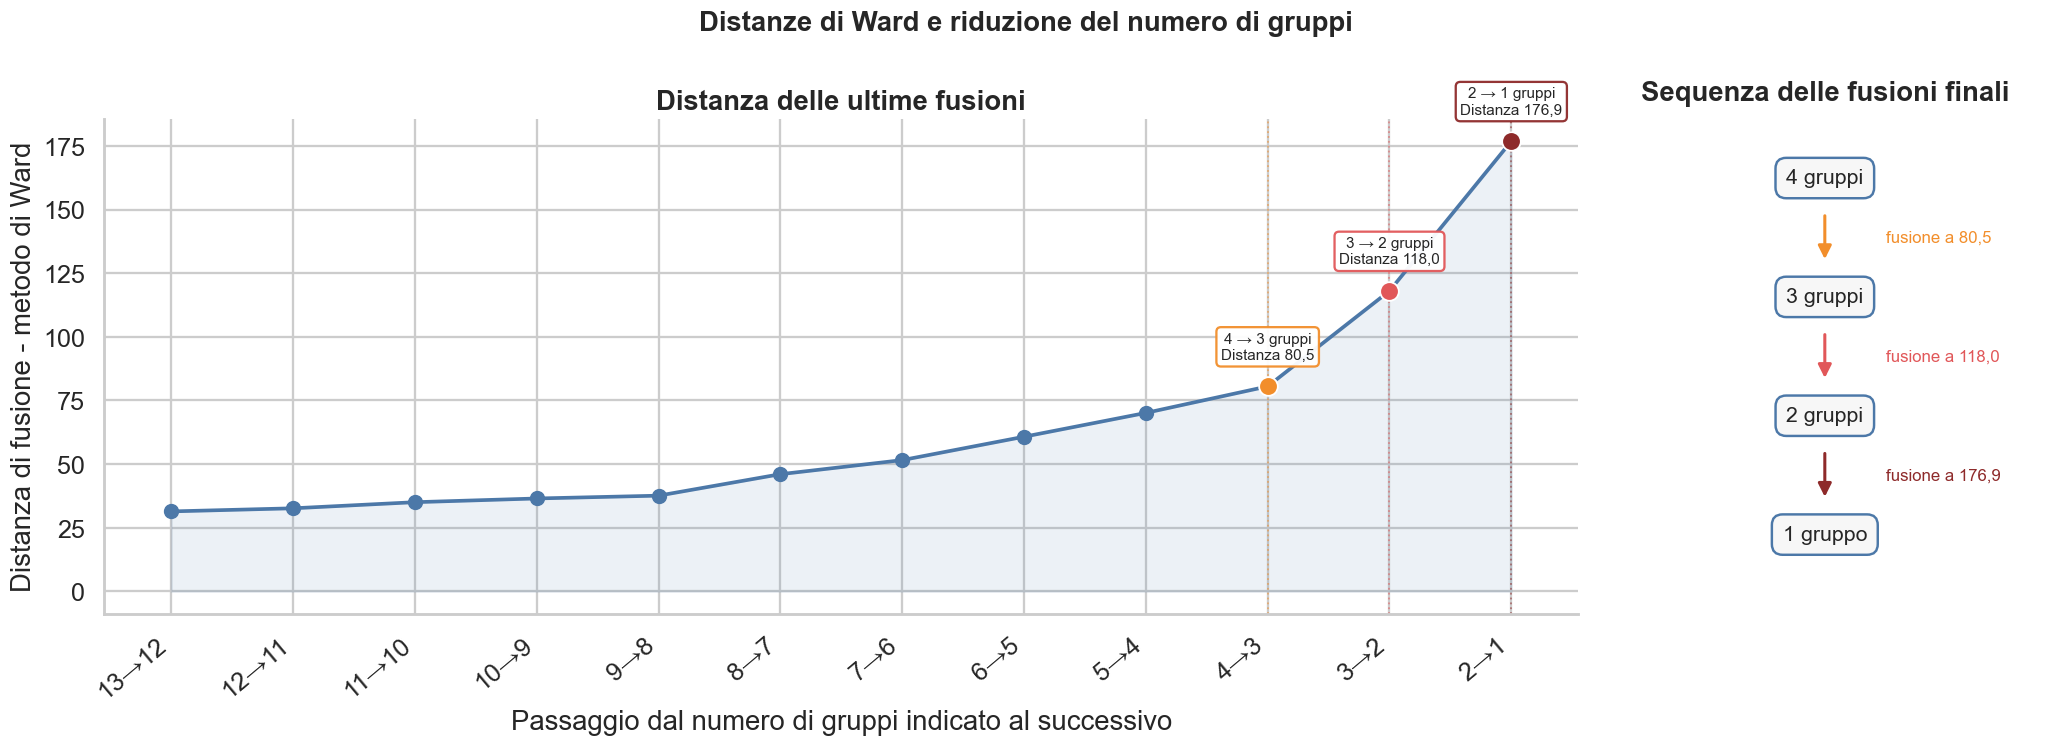

In [19]:
# Versione annotata; il grafico originale viene conservato.
fig, (ax_curve, ax_flow) = plt.subplots(
    1, 2, figsize=(19, 7),
    gridspec_kw={'width_ratios': [3.4, 1]}
)

ax_curve.plot(
    positions, last_rows[:, 2], marker='o', linewidth=2.4,
    color='#4c78a8', label='Fusioni precedenti'
)
ax_curve.fill_between(
    positions, last_rows[:, 2], alpha=0.10, color='#4c78a8'
)

highlight_colors = ['#f28e2b', '#e15759', '#8e2a2a']
for position, color in zip(positions[-3:], highlight_colors):
    before = int(groups_before[position])
    distance = float(last_rows[position, 2])
    distance_text = f'{distance:.1f}'.replace('.', ',')
    ax_curve.scatter(
        position, distance, s=150, color=color,
        edgecolor='white', linewidth=1.2, zorder=5
    )
    ax_curve.axvline(
        position, color=color, linestyle=':', linewidth=1.2, alpha=0.55
    )
    ax_curve.annotate(
        f'{before} → {before - 1} gruppi\nDistanza {distance_text}',
        (position, distance),
        xytext=(0, 16), textcoords='offset points',
        ha='center', va='bottom', fontsize=10,
        bbox={
            'boxstyle': 'round,pad=0.3',
            'facecolor': 'white',
            'edgecolor': color,
            'alpha': 0.95,
        },
    )

ax_curve.set_title('Distanza delle ultime fusioni')
ax_curve.set_xlabel('Passaggio dal numero di gruppi indicato al successivo')
ax_curve.set_ylabel('Distanza di fusione - metodo di Ward')
ax_curve.set_xticks(positions)
ax_curve.set_xticklabels(transition_labels, rotation=40, ha='right')

ax_flow.set_xlim(0, 1)
ax_flow.set_ylim(0, 1)
ax_flow.axis('off')
ax_flow.set_title('Sequenza delle fusioni finali', pad=12)

flow_groups = [4, 3, 2, 1]
flow_y = [0.88, 0.64, 0.40, 0.16]
flow_distances = [80.5, 118.0, 176.9]
flow_colors = ['#f28e2b', '#e15759', '#8e2a2a']

for group_count, y in zip(flow_groups, flow_y):
    label = '1 gruppo' if group_count == 1 else f'{group_count} gruppi'
    ax_flow.text(
        0.5, y, label, ha='center', va='center', fontsize=14,
        bbox={
            'boxstyle': 'round,pad=0.5',
            'facecolor': '#f7f7f7',
            'edgecolor': '#4c78a8',
            'linewidth': 1.6,
        },
    )

for index, (distance, color) in enumerate(
    zip(flow_distances, flow_colors)
):
    y_start = flow_y[index] - 0.07
    y_end = flow_y[index + 1] + 0.07
    ax_flow.annotate(
        '', xy=(0.5, y_end), xytext=(0.5, y_start),
        arrowprops={'arrowstyle': '-|>', 'color': color, 'linewidth': 2}
    )
    ax_flow.text(
        0.64, (y_start + y_end) / 2,
        f'fusione a {distance:.1f}'.replace('.', ','),
        ha='left', va='center', fontsize=11, color=color
    )

fig.suptitle(
    'Distanze di Ward e riduzione del numero di gruppi',
    fontsize=18, fontweight='bold'
)
fig.tight_layout()
fig.savefig(
    FIG_DIR / '10b_distanze_fusione_annotata.png',
    dpi=300, bbox_inches='tight'
)
plt.show()

### 7.3 Valutazione dei possibili tagli

Dopo aver costruito l'albero vengono esaminati i tagli da due a sei gruppi. La silhouette misura la separazione ottenuta da ciascun taglio. I risultati vengono affiancati a quelli di K-Means soltanto per osservare come cambia la qualità della suddivisione al variare del metodo.

,Silhouette gerarchico,Gruppo più piccolo,Gruppo più grande
Numero di gruppi,,,
2,0.3398,394,1692
3,0.2406,394,1030
4,0.1897,347,683
5,0.1814,301,683
6,0.1797,230,453


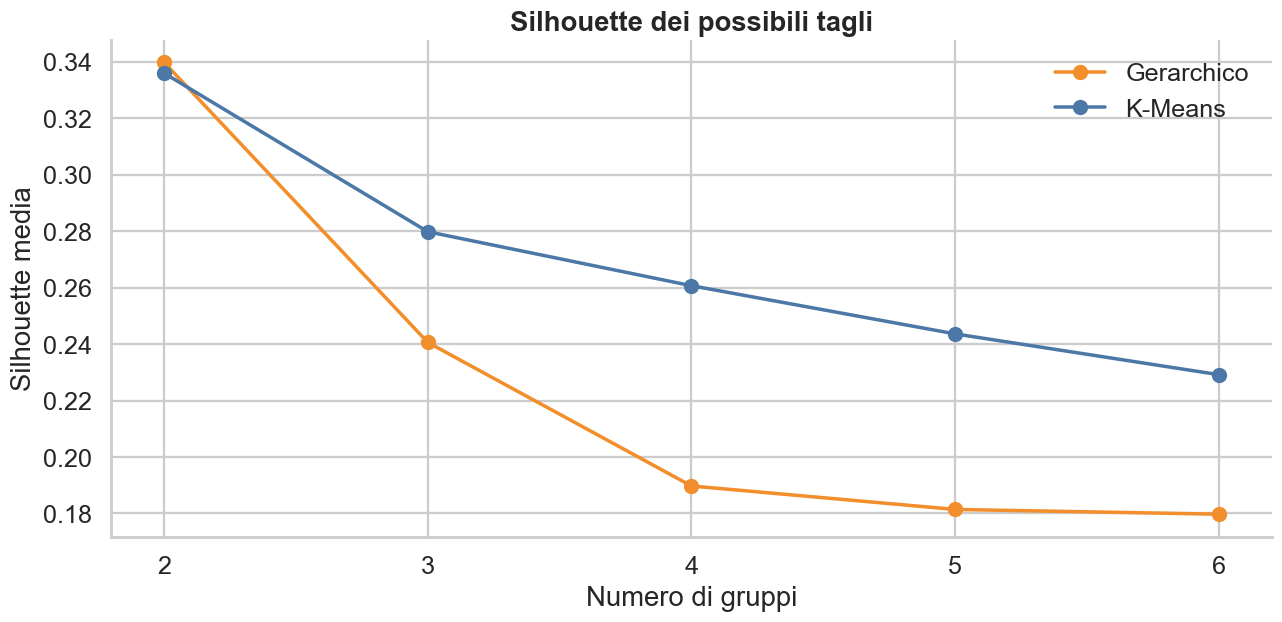

Taglio con silhouette più elevata: 2 gruppi


In [20]:
hierarchical_labels = {}
hierarchical_rows = []

for k in range(2, 7):
    labels = cut_tree(linkage_matrix, n_clusters=k).reshape(-1)
    hierarchical_labels[k] = labels
    counts = np.bincount(labels)
    hierarchical_rows.append({
        'Numero di gruppi': k,
        'Silhouette gerarchico': silhouette_score(X_pca, labels),
        'Gruppo più piccolo': counts.min(),
        'Gruppo più grande': counts.max(),
    })

hierarchical_table = pd.DataFrame(hierarchical_rows).set_index('Numero di gruppi')
display(
    hierarchical_table.style.format({
        'Silhouette gerarchico': '{:.4f}',
        'Gruppo più piccolo': '{:.0f}',
        'Gruppo più grande': '{:.0f}',
    }).highlight_max(subset=['Silhouette gerarchico'], color='#c7e9c0')
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    hierarchical_table.index,
    hierarchical_table['Silhouette gerarchico'],
    marker='o',
    linewidth=2.3,
    color='#f28e2b',
    label='Gerarchico',
)
ax.plot(
    selection_table.index,
    selection_table['Silhouette'],
    marker='o',
    linewidth=2.3,
    color='#4c78a8',
    label='K-Means',
)
ax.set_title('Silhouette dei possibili tagli')
ax.set_xlabel('Numero di gruppi')
ax.set_ylabel('Silhouette media')
ax.set_xticks(range(2, 7))
ax.legend()

fig.tight_layout()
fig.savefig(FIG_DIR / '11_valutazione_tagli_gerarchici.png', dpi=300, bbox_inches='tight')
plt.show()

best_hierarchical_k = int(hierarchical_table['Silhouette gerarchico'].idxmax())
print(f'Taglio con silhouette più elevata: {best_hierarchical_k} gruppi')

### 7.4 Interpretazione del taglio

Le due fusioni finali avvengono a distanze nettamente superiori alle precedenti. Insieme alla silhouette, questo indica che il taglio più netto della gerarchia è quello a due macro-gruppi. Le medie seguenti servono a interpretarli; i nomi non vengono imposti durante il calcolo.

In [21]:
PRIMARY_HIERARCHICAL_K = best_hierarchical_k
primary_hierarchical_labels = hierarchical_labels[PRIMARY_HIERARCHICAL_K]

primary_hierarchical_summary = (
    df_top.assign(Gruppo_gerarchico=primary_hierarchical_labels)
    .groupby('Gruppo_gerarchico')
    .agg(
        Giocatori=('Name', 'size'),
        OVR_medio=('OVR', 'mean'),
        PAC=('PAC', 'mean'),
        SHO=('SHO', 'mean'),
        PAS=('PAS', 'mean'),
        DRI=('DRI', 'mean'),
        DEF=('DEF', 'mean'),
        PHY=('PHY', 'mean'),
    )
)
display(primary_hierarchical_summary.style.format({
    'Giocatori': '{:.0f}',
    'OVR_medio': '{:.2f}',
    'PAC': '{:.1f}', 'SHO': '{:.1f}', 'PAS': '{:.1f}',
    'DRI': '{:.1f}', 'DEF': '{:.1f}', 'PHY': '{:.1f}',
}))

,Giocatori,OVR_medio,PAC,SHO,PAS,DRI,DEF,PHY
Gruppo_gerarchico,,,,,,,,
0,1692,78.62,74.8,70.6,73.4,77.6,58.8,71.4
1,394,78.26,64.3,43.9,62.0,64.4,79.1,77.7


### 7.5 Confronto a tre gruppi con K-Means

Il taglio a due gruppi è la scelta più forte dal punto di vista statistico. Tuttavia, per verificare la robustezza dei tre profili calcistici già individuati, si osserva anche il taglio dell'albero a tre gruppi. Questa è un'analisi di confronto e non modifica la scelta principale del metodo gerarchico.

,Giocatori,PAC,SHO,PAS,DRI,DEF,PHY
Profilo gerarchico,,,,,,,
Profilo offensivo,662,79.1,75.7,70.5,78.3,41.5,69.0
Profilo di manovra,1030,72.0,67.3,75.2,77.2,70.0,73.0
Profilo difensivo,394,64.3,43.9,62.0,64.4,79.1,77.7


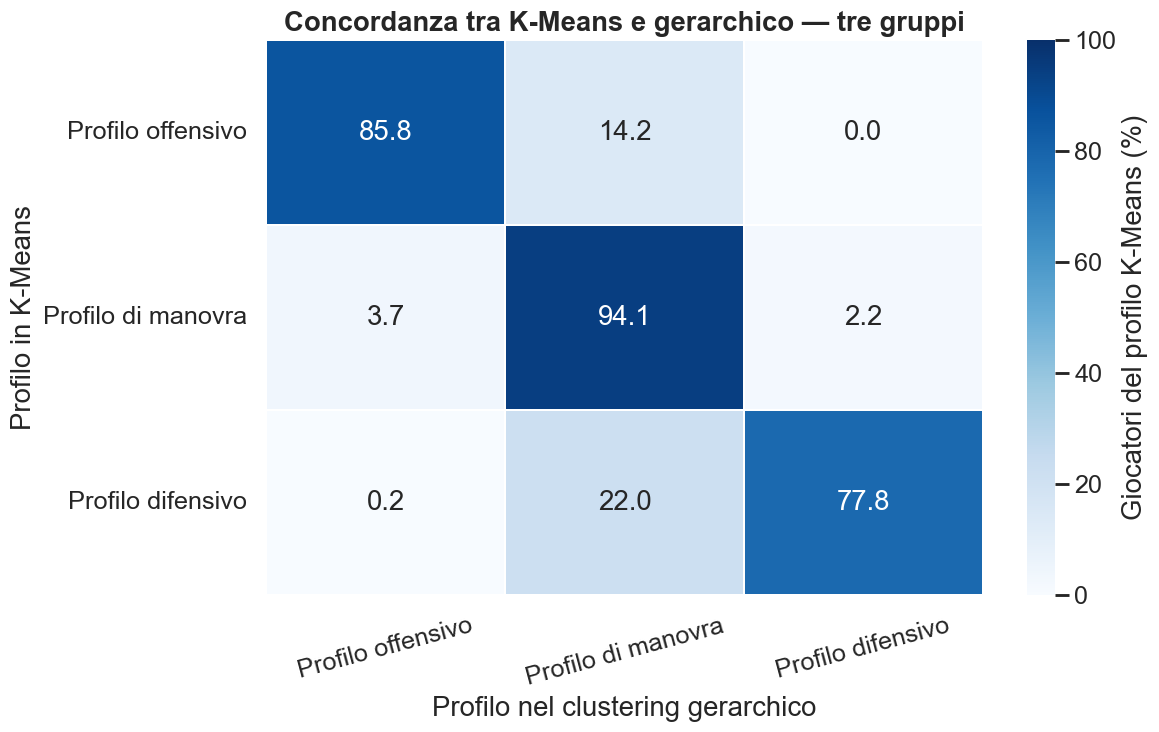

In [22]:
HIERARCHICAL_COMPARISON_K = 3
labels_hierarchical_3 = hierarchical_labels[HIERARCHICAL_COMPARISON_K]

df_hierarchical = df_top.copy()
df_hierarchical['Cluster_gerarchico'] = labels_hierarchical_3
hierarchical_means_3 = df_hierarchical.groupby('Cluster_gerarchico')[face_stats].mean()

hier_offensive_id = int(hierarchical_means_3['SHO'].idxmax())
hier_defensive_id = int(hierarchical_means_3['DEF'].idxmax())
hier_manovra_id = int(next(
    value for value in hierarchical_means_3.index
    if value not in {hier_offensive_id, hier_defensive_id}
))

hierarchical_names = {
    hier_offensive_id: 'Profilo offensivo',
    hier_manovra_id: 'Profilo di manovra',
    hier_defensive_id: 'Profilo difensivo',
}
df_hierarchical['Profilo gerarchico'] = (
    df_hierarchical['Cluster_gerarchico'].map(hierarchical_names)
)

hierarchical_profile_summary = (
    df_hierarchical.groupby('Profilo gerarchico')[face_stats]
    .mean()
    .reindex(profile_order)
)
hierarchical_profile_summary.insert(
    0,
    'Giocatori',
    df_hierarchical['Profilo gerarchico'].value_counts().reindex(profile_order),
)
display(hierarchical_profile_summary.style.format({
    'Giocatori': '{:.0f}',
    'PAC': '{:.1f}', 'SHO': '{:.1f}', 'PAS': '{:.1f}',
    'DRI': '{:.1f}', 'DEF': '{:.1f}', 'PHY': '{:.1f}',
}))

agreement = pd.crosstab(
    df_clustered['Profilo'],
    df_hierarchical['Profilo gerarchico'],
    normalize='index',
).mul(100).reindex(index=profile_order, columns=profile_order)

fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(
    agreement,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    vmin=0,
    vmax=100,
    linewidths=1,
    cbar_kws={'label': 'Giocatori del profilo K-Means (%)'},
    ax=ax,
)
ax.set_title('Concordanza tra K-Means e gerarchico — tre gruppi')
ax.set_xlabel('Profilo nel clustering gerarchico')
ax.set_ylabel('Profilo in K-Means')
ax.tick_params(axis='x', rotation=15)
ax.tick_params(axis='y', rotation=0)
fig.tight_layout()
fig.savefig(FIG_DIR / '12_confronto_kmeans_gerarchico.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Conclusioni sul clustering gerarchico

- La gerarchia è stata costruita integralmente senza fissare in anticipo il numero di cluster.
- Le distanze delle fusioni finali e la silhouette indicano due macro-gruppi come taglio statisticamente più netto.
- Il taglio a tre gruppi ha una separazione inferiore, ma ricostruisce i profili offensivo, di manovra e difensivo già osservati con K-Means.
- Le differenze fra i due algoritmi riguardano soprattutto i giocatori con caratteristiche intermedie, coerentemente con la sovrapposizione osservata nel grafico della silhouette.

Il risultato gerarchico rafforza quindi una lettura prudente: nel dataset esistono strutture riconoscibili, ma i profili non costituiscono categorie completamente separate.

In [23]:
print('RISULTATI DEL CLUSTERING GERARCHICO')
print('-' * 60)
print('Gerarchia costruita senza numero di cluster prefissato')
print(f'Taglio con silhouette migliore: k={best_hierarchical_k}')
print(
    f'Silhouette gerarchico k=2: '
    f'{hierarchical_table.loc[2, "Silhouette gerarchico"]:.4f}'
)
print(
    f'Silhouette gerarchico k=3: '
    f'{hierarchical_table.loc[3, "Silhouette gerarchico"]:.4f}'
)

RISULTATI DEL CLUSTERING GERARCHICO
------------------------------------------------------------
Gerarchia costruita senza numero di cluster prefissato
Taglio con silhouette migliore: k=2
Silhouette gerarchico k=2: 0.3398
Silhouette gerarchico k=3: 0.2406


## 9. DBSCAN

DBSCAN forma i cluster cercando zone sufficientemente dense e identifica come rumore i punti che non appartengono a tali zone. A differenza di K-Means non richiede il numero di gruppi, ma dipende da due parametri:

- `eps`: raggio entro il quale vengono cercati i vicini;
- `min_samples`: numero minimo di osservazioni richiesto per definire una zona densa.

L'analisi utilizza le stesse sei componenti PCA dei metodi precedenti. Non si cerca una combinazione di parametri che produca necessariamente tre gruppi: viene invece studiata la sensibilità del risultato.

In [24]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

BASE_MIN_SAMPLES = 2 * N_COMPONENTS
print(f'Dimensioni dello spazio PCA: {N_COMPONENTS}')
print(f'Valore iniziale di min_samples: {BASE_MIN_SAMPLES}')

Dimensioni dello spazio PCA: 6
Valore iniziale di min_samples: 12


### 9.1 Distanza dai vicini più prossimi

Come punto di partenza si considera `min_samples = 12`, pari al doppio delle sei dimensioni utilizzate. Non è una regola obbligatoria: per questo verranno controllati anche valori inferiori e superiori.

Per ogni giocatore viene calcolata la distanza dal dodicesimo vicino. Un cambiamento netto nella curva potrebbe suggerire un valore di `eps`; una curva graduale segnala invece che non esiste un confine di densità evidente.

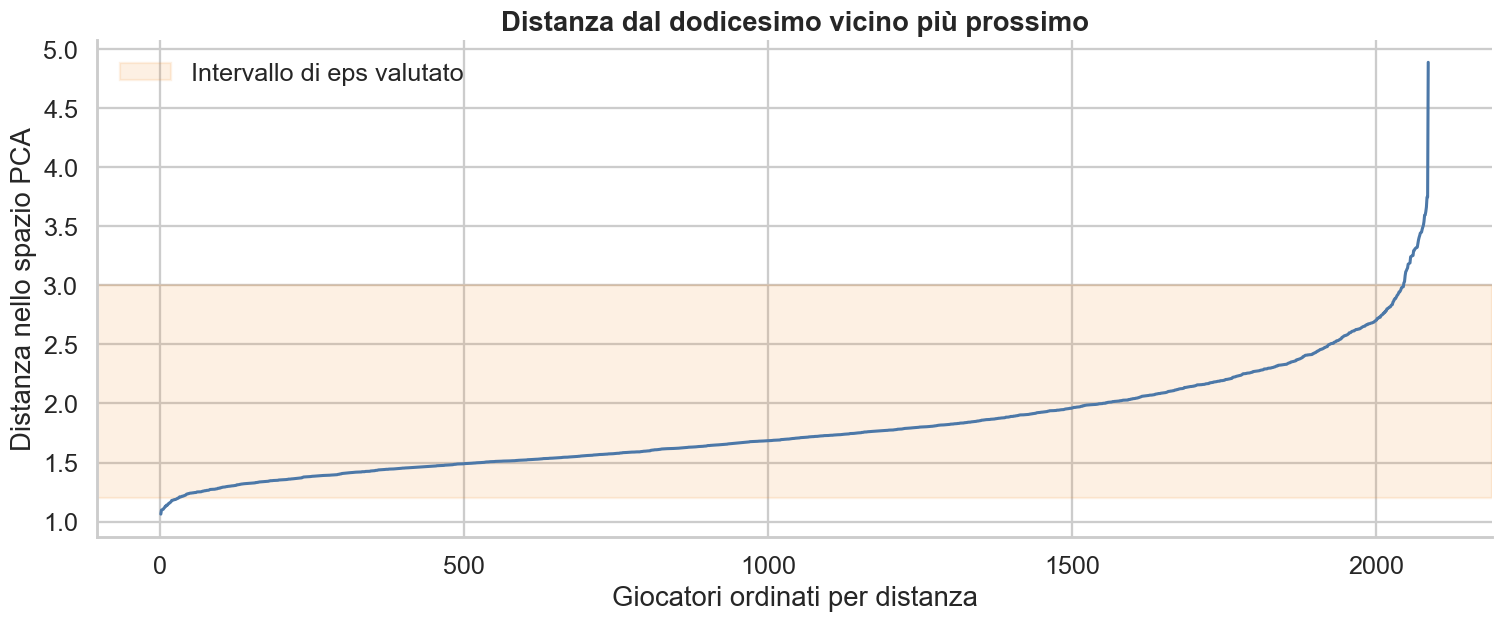

,Distanza
0.500000,1.705
0.750000,2.012
0.900000,2.385
0.950000,2.655
0.990000,3.314


In [25]:
nearest_neighbors = NearestNeighbors(n_neighbors=BASE_MIN_SAMPLES)
nearest_neighbors.fit(X_pca)
neighbor_distances, _ = nearest_neighbors.kneighbors(X_pca)
k_distances = np.sort(neighbor_distances[:, -1])

EPS_VALUES = np.round(
    np.concatenate([np.arange(1.2, 2.41, 0.1), [2.6, 2.8, 3.0]]),
    1,
)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(
    np.arange(1, len(k_distances) + 1),
    k_distances,
    color='#4c78a8',
    linewidth=2,
)
ax.axhspan(
    EPS_VALUES.min(),
    EPS_VALUES.max(),
    color='#f28e2b',
    alpha=0.13,
    label='Intervallo di eps valutato',
)
ax.set_title('Distanza dal dodicesimo vicino più prossimo')
ax.set_xlabel('Giocatori ordinati per distanza')
ax.set_ylabel('Distanza nello spazio PCA')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig(FIG_DIR / '13_distanze_vicini_dbscan.png', dpi=300, bbox_inches='tight')
plt.show()

quantiles = pd.Series(k_distances).quantile([0.50, 0.75, 0.90, 0.95, 0.99])
display(quantiles.rename('Distanza').to_frame().style.format('{:.3f}'))

### 9.2 Sensibilità ai parametri

Vengono confrontati sette valori di `min_samples`, da 6 a 18 con passo 2. L'estremo inferiore coincide con il numero di componenti PCA e rappresenta una scelta meno restrittiva; 12 resta il valore di riferimento, pari al doppio delle dimensioni; 18 costituisce un controllo più restrittivo. Il passo 2 permette di osservare le transizioni senza introdurre un numero eccessivo di configurazioni quasi equivalenti. Per ogni combinazione si registrano il numero di cluster, la percentuale di rumore e la silhouette calcolata escludendo il rumore. Le celle vuote nella relativa heatmap indicano le configurazioni in cui la silhouette non è definibile, perché DBSCAN produce meno di due cluster.

La silhouette da sola non basta per scegliere i parametri: un valore apparentemente alto può derivare da pochissimi gruppi molto piccoli e da una grande quantità di osservazioni scartate come rumore.

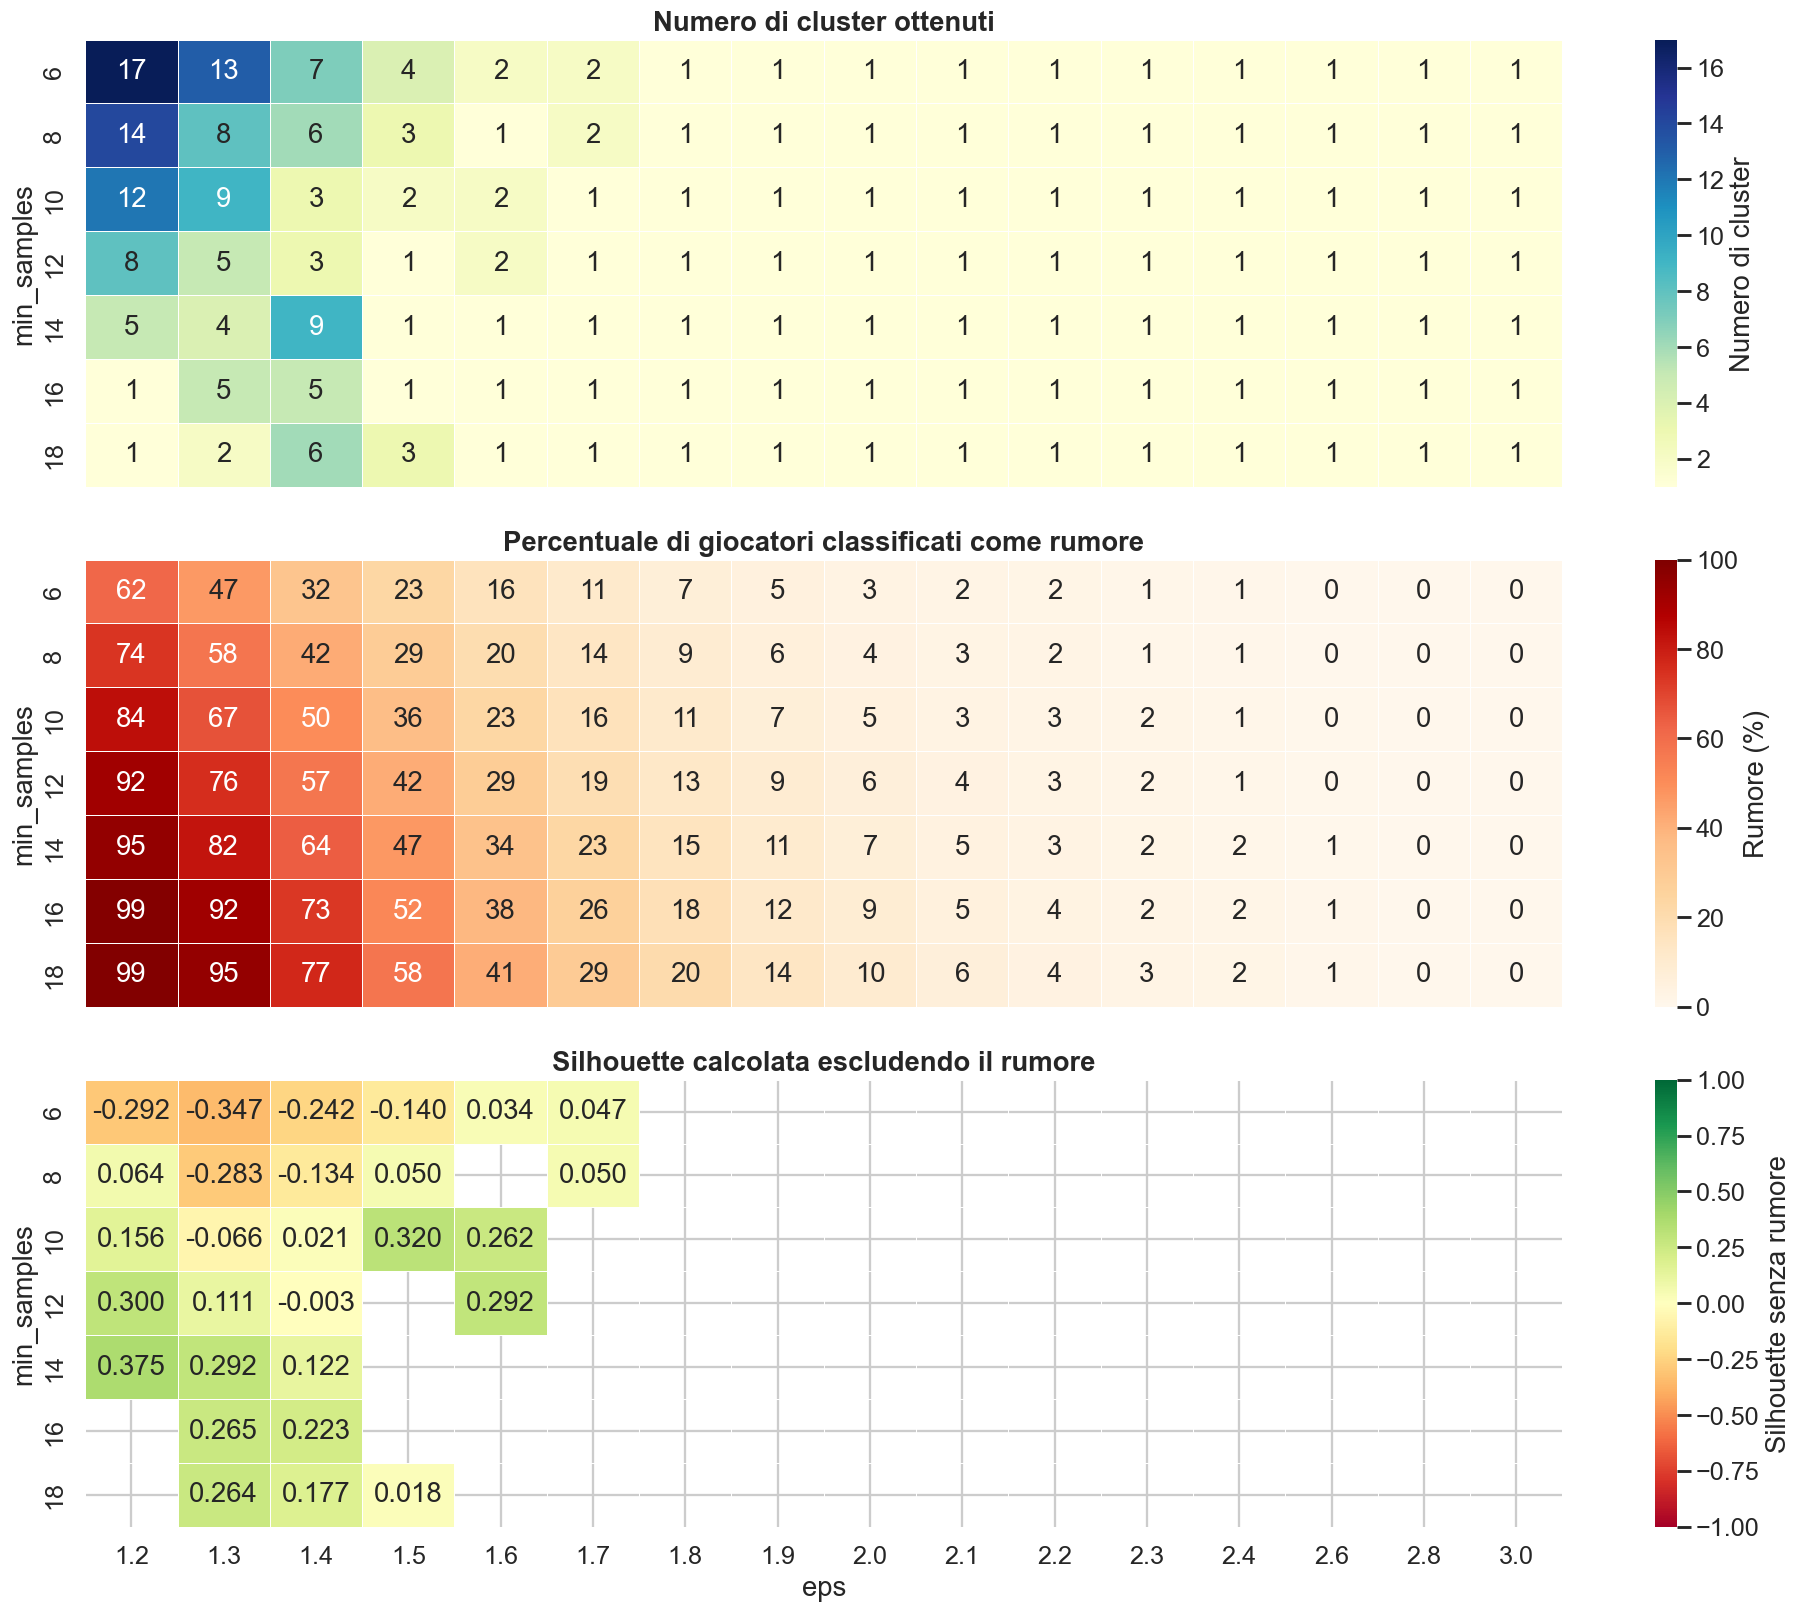

,min_samples,eps,Numero di cluster,Rumore (%),Silhouette senza rumore,Cluster più piccolo,Cluster più grande
0,6,1.2,17,61.9,-0.292,3,659
1,6,1.3,13,46.5,-0.347,3,1045
2,6,1.4,7,32.5,-0.242,4,1371
3,6,1.5,4,23.1,-0.140,4,1592
4,6,1.6,2,15.6,0.034,6,1754
5,6,1.7,2,11.3,0.047,9,1841
6,8,1.2,14,73.9,0.064,6,303
7,8,1.3,8,57.6,-0.283,6,797
8,8,1.4,6,41.8,-0.134,5,1179
9,8,1.5,3,29.2,0.050,6,1462


In [26]:
MIN_SAMPLES_VALUES = [6, 8, 10, 12, 14, 16, 18]
dbscan_rows = []
dbscan_models = {}

for min_samples in MIN_SAMPLES_VALUES:
    for eps in EPS_VALUES:
        model = DBSCAN(eps=float(eps), min_samples=min_samples)
        labels = model.fit_predict(X_pca)
        dbscan_models[(min_samples, float(eps))] = labels

        non_noise = labels != -1
        cluster_ids_dbscan = np.unique(labels[non_noise])
        n_clusters = len(cluster_ids_dbscan)
        noise_count = int((~non_noise).sum())

        if n_clusters >= 2 and non_noise.sum() > n_clusters:
            silhouette_without_noise = silhouette_score(
                X_pca[non_noise], labels[non_noise]
            )
            cluster_sizes = np.bincount(labels[non_noise])
            smallest_cluster = int(cluster_sizes.min())
            largest_cluster = int(cluster_sizes.max())
        else:
            silhouette_without_noise = np.nan
            smallest_cluster = np.nan
            largest_cluster = int(non_noise.sum()) if n_clusters == 1 else np.nan

        dbscan_rows.append({
            'min_samples': min_samples,
            'eps': float(eps),
            'Numero di cluster': n_clusters,
            'Rumore (%)': noise_count / len(labels) * 100,
            'Silhouette senza rumore': silhouette_without_noise,
            'Cluster più piccolo': smallest_cluster,
            'Cluster più grande': largest_cluster,
        })

dbscan_results = pd.DataFrame(dbscan_rows)

cluster_pivot = dbscan_results.pivot(
    index='min_samples', columns='eps', values='Numero di cluster'
)
noise_pivot = dbscan_results.pivot(
    index='min_samples', columns='eps', values='Rumore (%)'
)
silhouette_pivot = dbscan_results.pivot(
    index='min_samples', columns='eps', values='Silhouette senza rumore'
)

fig, axes = plt.subplots(3, 1, figsize=(18, 15), sharex=True)
sns.heatmap(
    cluster_pivot,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Numero di cluster'},
    ax=axes[0],
)
axes[0].set_title('Numero di cluster ottenuti')
axes[0].set_xlabel('')
axes[0].set_ylabel('min_samples')

sns.heatmap(
    noise_pivot,
    annot=True,
    fmt='.0f',
    cmap='OrRd',
    linewidths=0.5,
    vmin=0,
    vmax=100,
    cbar_kws={'label': 'Rumore (%)'},
    ax=axes[1],
)
axes[1].set_title('Percentuale di giocatori classificati come rumore')
axes[1].set_xlabel('')
axes[1].set_ylabel('min_samples')

sns.heatmap(
    silhouette_pivot,
    annot=True,
    fmt='.3f',
    cmap='RdYlGn',
    center=0,
    vmin=-1,
    vmax=1,
    mask=silhouette_pivot.isna(),
    linewidths=0.5,
    cbar_kws={'label': 'Silhouette senza rumore'},
    ax=axes[2],
)
axes[2].set_title('Silhouette calcolata escludendo il rumore')
axes[2].set_xlabel('eps')
axes[2].set_ylabel('min_samples')

fig.tight_layout()
fig.savefig(FIG_DIR / '14_sensibilita_dbscan.png', dpi=300, bbox_inches='tight')
plt.show()

candidate_rows = (
    dbscan_results.loc[dbscan_results['Numero di cluster'] >= 2]
    .sort_values(['min_samples', 'eps'])
    .reset_index(drop=True)
)
display(candidate_rows.style.format({
    'eps': '{:.1f}',
    'Rumore (%)': '{:.1f}',
    'Silhouette senza rumore': '{:.3f}',
    'Cluster più piccolo': '{:.0f}',
    'Cluster più grande': '{:.0f}',
}))

### 9.3 Due configurazioni con scopi differenti

La configurazione con la silhouette più elevata e quella scelta per il confronto a tre cluster rispondono a domande diverse. La prima serve a mostrare perché la silhouette non possa essere utilizzata da sola; la seconda permette un confronto descrittivo con le suddivisioni in tre gruppi esaminate con gli altri metodi. Nessuna delle due viene considerata una soluzione ottimale.

#### 9.3.1 Configurazione con silhouette massima

In [27]:
max_silhouette_index = dbscan_results['Silhouette senza rumore'].idxmax()
max_silhouette_row = dbscan_results.loc[max_silhouette_index]

MAX_SIL_EPS = float(max_silhouette_row['eps'])
MAX_SIL_MIN_SAMPLES = int(max_silhouette_row['min_samples'])
max_silhouette_labels = dbscan_models[(MAX_SIL_MIN_SAMPLES, MAX_SIL_EPS)]
max_silhouette_non_noise = max_silhouette_labels != -1
max_silhouette_sizes = pd.Series(
    max_silhouette_labels[max_silhouette_non_noise]
).value_counts().sort_index()
max_silhouette_noise = int((~max_silhouette_non_noise).sum())

max_silhouette_summary = pd.DataFrame({
    'eps': [MAX_SIL_EPS],
    'min_samples': [MAX_SIL_MIN_SAMPLES],
    'Numero di cluster': [int(max_silhouette_row['Numero di cluster'])],
    'Rumore': [max_silhouette_noise],
    'Rumore (%)': [float(max_silhouette_row['Rumore (%)'])],
    'Silhouette senza rumore': [float(max_silhouette_row['Silhouette senza rumore'])],
    'Dimensioni dei cluster': [', '.join(map(str, max_silhouette_sizes.tolist()))],
})

display(max_silhouette_summary.style.format({
    'eps': '{:.1f}',
    'Rumore (%)': '{:.1f}',
    'Silhouette senza rumore': '{:.3f}',
}))

,eps,min_samples,Numero di cluster,Rumore,Rumore (%),Silhouette senza rumore,Dimensioni dei cluster
0,1.2,14,5,1988,95.3,0.375,"14, 35, 21, 14, 14"


Il massimo, pari a circa **0,375**, si osserva con `eps = 1.2` e `min_samples = 14`. La configurazione produce cinque cluster di 14, 35, 21, 14 e 14 giocatori, ma classifica come rumore 1.988 osservazioni su 2.086, pari al **95,3%** del campione. La silhouette è quindi calcolata su appena 98 giocatori e descrive soltanto questa piccola parte dei dati: il valore elevato non rappresenta la qualità della partizione sull'intero campione.

Anche altre silhouette relativamente elevate dipendono da partizioni molto sbilanciate. Aumentando `eps`, il rumore diminuisce ma le osservazioni confluiscono rapidamente in un unico cluster. Non emerge quindi una zona di parametri vicini che produca strutture stabili e bilanciate.

#### 9.3.2 Configurazione a tre cluster per il confronto

Tra le configurazioni analizzate che producono tre cluster, si utilizza `eps = 1.5` e `min_samples = 8` per il confronto descrittivo con gli altri metodi. Rispetto alle altre soluzioni a tre gruppi considerate, riduce la quota di rumore al **29,2%**, ma rimane fortemente sbilanciata: i cluster comprendono 1.462, 6 e 9 giocatori e la silhouette senza rumore è circa **0,050**. Questa scelta non dimostra quindi l'esistenza di tre profili significativi; serve soltanto a mostrare il comportamento di DBSCAN quando si richiede una configurazione confrontabile con le partizioni a tre gruppi già esaminate.

In [28]:
# Configurazione a tre cluster usata esclusivamente per il confronto descrittivo.
DBSCAN_EPS = 1.5
DBSCAN_MIN_SAMPLES = 8
dbscan_labels = dbscan_models[(DBSCAN_MIN_SAMPLES, DBSCAN_EPS)]

dbscan_non_noise = dbscan_labels != -1
dbscan_cluster_ids = sorted(np.unique(dbscan_labels[dbscan_non_noise]))
dbscan_n_clusters = len(dbscan_cluster_ids)
dbscan_noise_count = int((~dbscan_non_noise).sum())
dbscan_noise_pct = dbscan_noise_count / len(dbscan_labels) * 100

if dbscan_n_clusters >= 2:
    dbscan_silhouette = silhouette_score(
        X_pca[dbscan_non_noise], dbscan_labels[dbscan_non_noise]
    )
else:
    dbscan_silhouette = np.nan

dbscan_counts = pd.Series(dbscan_labels).value_counts().sort_index()
dbscan_summary = pd.DataFrame({
    'Gruppo': [
        'Rumore' if label == -1 else f'Cluster {label}'
        for label in dbscan_counts.index
    ],
    'Giocatori': dbscan_counts.values,
})
dbscan_summary['Percentuale'] = dbscan_summary['Giocatori'] / len(dbscan_labels) * 100

print(
    'Configurazione a tre cluster per il confronto: '
    f'eps = {DBSCAN_EPS}, min_samples = {DBSCAN_MIN_SAMPLES}'
)
display(dbscan_summary.style.format({'Percentuale': '{:.1f}%'}))
print(f'Numero di cluster: {dbscan_n_clusters}')
print(f'Rumore: {dbscan_noise_count:,} giocatori ({dbscan_noise_pct:.1f}%)')
print(f'Silhouette senza rumore: {dbscan_silhouette:.4f}')

Configurazione a tre cluster per il confronto: eps = 1.5, min_samples = 8


,Gruppo,Giocatori,Percentuale
0,Rumore,609,29.2%
1,Cluster 0,1462,70.1%
2,Cluster 1,6,0.3%
3,Cluster 2,9,0.4%


Numero di cluster: 3
Rumore: 609 giocatori (29.2%)
Silhouette senza rumore: 0.0497


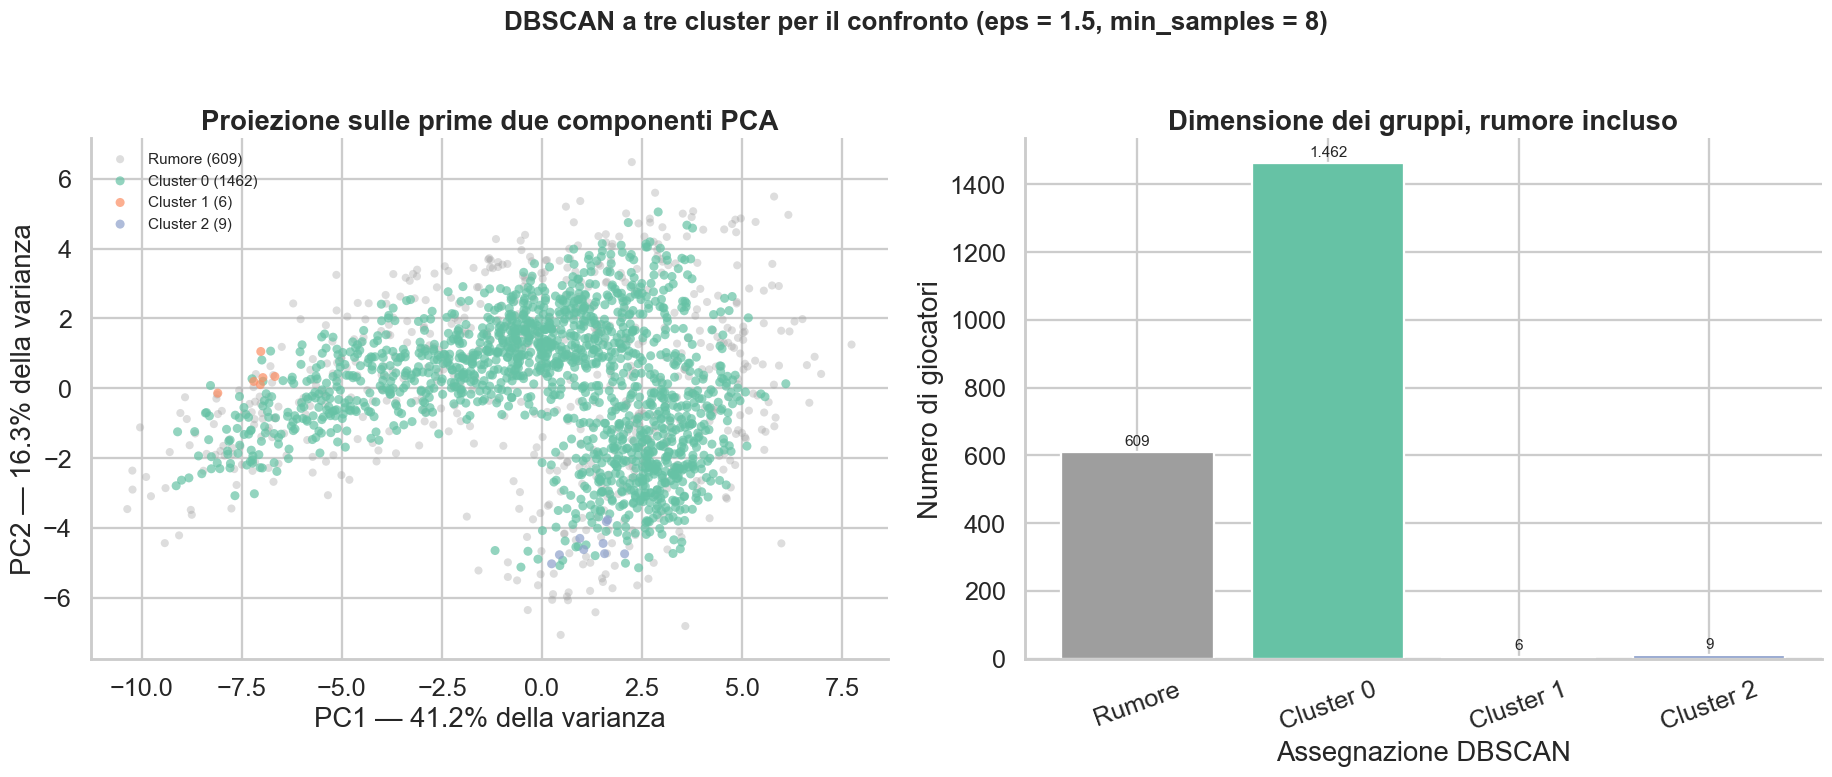

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

noise_mask = dbscan_labels == -1
axes[0].scatter(
    X_pca[noise_mask, 0],
    X_pca[noise_mask, 1],
    s=28,
    alpha=0.35,
    color='#9e9e9e',
    label=f'Rumore ({noise_mask.sum()})',
    edgecolors='none',
)

dbscan_colors = sns.color_palette('Set2', n_colors=max(dbscan_n_clusters, 1))
for color, cluster_id in zip(dbscan_colors, dbscan_cluster_ids):
    mask = dbscan_labels == cluster_id
    axes[0].scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=35,
        alpha=0.70,
        color=color,
        label=f'Cluster {cluster_id} ({mask.sum()})',
        edgecolors='none',
    )

axes[0].set_title('Proiezione sulle prime due componenti PCA')
axes[0].set_xlabel(f'PC1 — {pca.explained_variance_ratio_[0] * 100:.1f}% della varianza')
axes[0].set_ylabel(f'PC2 — {pca.explained_variance_ratio_[1] * 100:.1f}% della varianza')
axes[0].legend(fontsize=10)

bar_colors = [
    '#9e9e9e' if group == 'Rumore' else dbscan_colors[int(group.split()[-1])]
    for group in dbscan_summary['Gruppo']
]
axes[1].bar(
    dbscan_summary['Gruppo'],
    dbscan_summary['Giocatori'],
    color=bar_colors,
)
axes[1].set_title('Dimensione dei gruppi, rumore incluso')
axes[1].set_xlabel('Assegnazione DBSCAN')
axes[1].set_ylabel('Numero di giocatori')
axes[1].tick_params(axis='x', rotation=20)

for index, value in enumerate(dbscan_summary['Giocatori']):
    label = f'{value:,}'.replace(',', '.')
    axes[1].text(index, value + 20, label, ha='center', fontsize=10)

fig.suptitle(
    f'DBSCAN a tre cluster per il confronto '
    f'(eps = {DBSCAN_EPS}, min_samples = {DBSCAN_MIN_SAMPLES})',
    fontsize=17,
    fontweight='bold',
    y=1.02,
)
fig.tight_layout()
fig.savefig(FIG_DIR / '15_risultato_dbscan.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Confronto finale dei metodi

La tabella riassume le configurazioni utilizzate nell'interpretazione. Per DBSCAN viene riportata la configurazione a tre cluster scelta esclusivamente per il confronto descrittivo. La sua silhouette è calcolata escludendo il rumore e non è quindi direttamente confrontabile con quelle degli altri metodi. La configurazione con silhouette massima resta separata perché esclude il 95,3% del campione.

In [30]:
final_comparison = pd.DataFrame({
    'Metodo': [
        'K-Means',
        'Gerarchico',
        'DBSCAN (3 cluster, confronto)',
    ],
    'Configurazione': [
        'k = 3',
        f'taglio a k = {best_hierarchical_k}',
        f'eps = {DBSCAN_EPS}, min_samples = {DBSCAN_MIN_SAMPLES}',
    ],
    'Numero di gruppi': [
        CHOSEN_K,
        best_hierarchical_k,
        dbscan_n_clusters,
    ],
    'Rumore (%)': [
        0.0,
        0.0,
        dbscan_noise_pct,
    ],
    'Silhouette': [
        selection_table.loc[CHOSEN_K, 'Silhouette'],
        hierarchical_table.loc[best_hierarchical_k, 'Silhouette gerarchico'],
        dbscan_silhouette,
    ],
    'Lettura del risultato': [
        'Tre profili calcistici interpretabili',
        'Due macro-gruppi statisticamente più netti',
        'Un gruppo dominante e due gruppi molto piccoli',
    ],
})

display(final_comparison.style.format({
    'Rumore (%)': '{:.1f}',
    'Silhouette': '{:.4f}',
}))

,Metodo,Configurazione,Numero di gruppi,Rumore (%),Silhouette,Lettura del risultato
0,K-Means,k = 3,3,0.0,0.2798,Tre profili calcistici interpretabili
1,Gerarchico,taglio a k = 2,2,0.0,0.3398,Due macro-gruppi statisticamente più netti
2,"DBSCAN (3 cluster, confronto)","eps = 1.5, min_samples = 8",3,29.2,0.0497,Un gruppo dominante e due gruppi molto piccoli


## 11. Conclusioni sul clustering

K-Means fornisce la rappresentazione più utile per descrivere tre profili calcistici, pur con una separazione soltanto moderata. L'approfondimento sui centrocampisti mostra che, eliminando le differenze tra reparti, emergono tre gruppi equilibrati riconducibili a profili centrali completi, offensivi ed esterni e mediani difensivi. Anche in questo caso le posizioni si sovrappongono e la silhouette rimane moderata, confermando che i ruoli calcistici non costituiscono categorie rigide. Il clustering gerarchico conferma l'esistenza di una struttura generale, ma indica che la divisione più netta è quella in due macro-gruppi.

DBSCAN non individua invece una partizione convincente. La griglia più fitta di `min_samples` conferma che non esiste una regione stabile di parametri: con valori piccoli di `eps` molti giocatori vengono classificati come rumore e compaiono gruppi molto piccoli; aumentando `eps`, le osservazioni confluiscono rapidamente in un unico grande cluster. Il massimo della silhouette, circa 0,375 con `eps = 1.2` e `min_samples = 14`, è fuorviante perché viene calcolato su appena 98 giocatori, mentre il 95,3% del campione è classificato come rumore.

Per il confronto descrittivo a tre gruppi è stata utilizzata la configurazione `eps = 1.5` e `min_samples = 8`. Essa riduce il rumore al 29,2%, ma produce cluster di 1.462, 6 e 9 giocatori e una silhouette di circa 0,050. Il risultato è quindi dominato da un unico gruppo e non conferma l'esistenza di tre profili significativi.

Il risultato non costituisce un errore dell'algoritmo: indica che, nello spazio delle caratteristiche utilizzato, i giocatori non formano regioni dense nettamente separate. I profili appaiono piuttosto come zone parzialmente sovrapposte di una distribuzione continua.